# capi-autoscaler benchmark analysis

Auto-generates scores, graphs and summaries per benchmark profile, mapped to the
research questions (RQ1-RQ4). Every figure and table is also written to
`exports/` (SVG+PNG, CSV+markdown) for the report.

Every run in `../results/` pools into the averages, so curation is by keeping
only the files you want counted (archive the rest). capi runs are split into
cohorts by source-file date (`loading.cohort_for`): `placementcontrol` (files
dated on/after 20260831) and `pre-placementcontrol`. Every chart and table
compares the placementcontrol cohort against the cas/karpenter baselines;
pre-placementcontrol numbers appear only in the RQ4 pre-vs-post comparison.

Re-run end to end after new benchmark data lands:
`uv run jupyter nbconvert --to notebook --execute --inplace analysis.ipynb`

<style>
pre { white-space: pre-wrap !important; overflow-wrap: break-word; }
</style>

## System under test: architecture

The controller runs as a pod in the management cluster; the `client` uses
in-cluster configuration, and the workload cluster is reached via the kubeconfig mounted at
`REMOTE_CONFIG_PATH`. The optimiser is a library call inside the controller
process, not a service. The Mermaid diagrams render in JupyterLab 4.1+;
nbconvert leaves the mermaid source as a code block.

```mermaid
flowchart TB
    subgraph mgmt["Management cluster (client = in-cluster config)"]
        subgraph proc["capi-autoscaler pod (autoscaler crate)"]
            rec["controller.rs reconcile<br/>Idle / WaitingForPendingPods / WaitingForNodes"]
            bridge["autoscaler/src/optimiser.rs<br/>plan_scale_up, solve_scale_up, scale_up"]
            solver["optimiser crate<br/>solver.rs optimise_placement<br/>optimise.rs CP-SAT model, beam_search.rs fallback"]
        end
        cr["Autoscale CR wikoion.dev/v1alpha1<br/>status: scaling_plan, planned_placements"]
        mds["MachineDeployments / MachineSets"]
        capi["CAPI / CAPA"]
    end

    subgraph workload["Workload cluster (remote_client)"]
        dep["Deployment creates pods<br/>label wikoion.dev/placement: managed"]
        map["MutatingAdmissionPolicy<br/>capi-autoscaler-placement-gate"]
        pods["Pending pods<br/>schedulingGate wikoion.dev/placement"]
        nodes["Nodes"]
        sched["kube-scheduler"]
    end

    capi ~~~ dep
    cr ~~~ dep

    dep --> map
    map -- "injects scheduling gate on CREATE" --> pods
    rec -- "watches: unschedulable pods" --> pods
    rec -- "watches: Ready transitions" --> nodes
    rec --> bridge
    bridge -- "SolverInput: MDs, pods,<br/>allowed_matrix, topology/affinity groups" --> solver
    solver -- "SolverResult: assignments, slots_used" --> bridge
    bridge -- "patch spec.replicas (scale_md)" --> mds
    bridge -- "store plan in status" --> cr
    mds --> capi
    capi -- "provision Machines, nodes join" --> nodes
    rec -- "place_pods_on_ready_nodes:<br/>set nominatedNodeName, remove gate" --> pods
    pods --> sched
    sched -- "binds pod to nominated node" --> nodes
```

Pods that fit existing capacity are nominated and ungated straight after
solving. Pods for new nodes wait until their node is Ready; each new Ready node
claims the lowest unclaimed solver slot for its MD. Hard zone-spread
deployments are held until all their nodes are Ready, then released round-robin
across zones.

How the data in this notebook is produced:

```mermaid
flowchart LR
    harness["Python harness<br/>benchmarks/harness, python -m benchmark.cli<br/>capi-autoscaler / cas / karpenter"]
    wc["Workload cluster"]
    log["Controller pod log<br/>'Solver result:' lines"]
    csv["../results/<br/>*_summary.csv, *_timeseries.csv, *_solver.csv"]
    sb["solver-bench, offline Rust crate<br/>benchmarks/solver-bench"]
    csv2["solverbench_*_rq2.csv / _rq3.csv"]
    nb["analysis.ipynb<br/>capi_bench_analysis package"]
    exports["exports/ figures, tables, summaries"]

    harness -- "inject workload pods, poll pods/nodes" --> wc
    harness -- "scrape solver metrics" --> log
    harness --> csv
    sb --> csv2
    csv --> nb
    csv2 --> nb
    nb --> exports
```

In [1]:
# Export the architecture diagrams above to exports/figures like every other
# figure. Pulls the mermaid source from the markdown cell so there is one copy.
import json
import re
from pathlib import Path

from capi_bench_analysis import export

cells = json.loads(Path("analysis.ipynb").read_text())["cells"]
arch = next(c for c in cells if c["cell_type"] == "markdown"
            and "".join(c["source"]).startswith("## System under test"))
blocks = re.findall(r"```mermaid\n(.*?)```", "".join(arch["source"]), re.S)
for source, name in zip(blocks, ["architecture_system", "architecture_pipeline"]):
    export.save_mermaid(source, name)
    print(f"exported {name}")

exported architecture_system


exported architecture_pipeline


In [2]:
# 0. Parameters and loading
%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd

from capi_bench_analysis import loading, stats, plotting, summaries, export

DATE_FILTER = None  # invalidated data is archived; set e.g. "20260830" to narrow
EXCLUDED_RUN_IDS = set()  # row-level drops for bad runs in otherwise good files

config = loading.load_harness_config()
summary = loading.load_summaries(date_filter=DATE_FILTER)
summary = summary[~summary["run_id"].isin(EXCLUDED_RUN_IDS)].reset_index(drop=True)
run_ids = set(summary["run_id"])
timeseries = loading.load_timeseries(run_ids, date_filter=DATE_FILTER)
solver = loading.load_solver_metrics(run_ids, date_filter=DATE_FILTER)
summary = loading.recompute_utilisation(summary, timeseries)

# main: baselines + placementcontrol capi; every RQ and cost section uses this.
# Pre-placementcontrol capi rows only feed the RQ4 pre-vs-post comparison.
# karpenter-consolidation runs hold the full window by design, so they only
# feed the consolidation section, not the RQ comparisons.
main = summary[(summary["cohort"] != "pre-placementcontrol")
               & (summary["autoscaler"] != "karpenter-consolidation")].reset_index(drop=True)
main_ids = set(main["run_id"])
consol = summary[summary["autoscaler"] == "karpenter-consolidation"].reset_index(drop=True)
prepost = summary[summary["autoscaler"] == "capi-autoscaler"].reset_index(drop=True)
instances = loading.explode_instance_counts(main, config.INSTANCE_HOURLY_COST)

print(f"{len(summary)} pooled summary rows by cohort: "
      f"{summary['cohort'].value_counts().to_dict()}; "
      f"{len(consol)} consolidation rows; "
      f"{len(timeseries)} timeseries points, {len(solver)} solver rows")

306 pooled summary rows by cohort: {'baseline': 198, 'placementcontrol': 90, 'pre-placementcontrol': 18}; 18 consolidation rows; 10097 timeseries points, 173 solver rows


## Data inventory

Pooled runs per profile/pod count/autoscaler/cohort. Every run in `../results/`
counts towards the means; drop a session by archiving its files, or single runs
via `EXCLUDED_RUN_IDS` in cell 0. `runs` tracks the number of retained runs
per scenario.

In [3]:
inventory = (summary.groupby(["profile", "pod_count", "autoscaler", "cohort"])
    .agg(runs=("run_id", "count"), timed_out=("timed_out", "sum"),
         source_files=("source_file", "nunique"))
    .reset_index())
export.save_table(inventory, "data_inventory")
inventory

,profile,pod_count,autoscaler,cohort,runs,timed_out,source_files
0,heavy-constrained,25,capi-autoscaler,placementcontrol,10,0,3
1,heavy-constrained,25,capi-autoscaler,pre-placementcontrol,2,0,1
2,heavy-constrained,25,cas,baseline,10,0,3
3,heavy-constrained,25,karpenter,baseline,10,0,4
4,heavy-constrained,25,karpenter-consolidation,baseline,2,0,2
5,heavy-constrained,50,capi-autoscaler,placementcontrol,10,0,3
6,heavy-constrained,50,capi-autoscaler,pre-placementcontrol,2,0,1
7,heavy-constrained,50,cas,baseline,10,0,4
8,heavy-constrained,50,karpenter,baseline,10,0,4
9,heavy-constrained,50,karpenter-consolidation,baseline,2,0,2


## RQ1: scale-up performance vs cas and Karpenter

Score tables (mean +/- 95% CI over non-timed-out runs) and comparison charts per
profile. Charts mark empty slots where an autoscaler's runs all timed out and
carry a footnote with the timeout counts (cas timed out in 2/10 runs at
heavy-constrained-100). The
100-pod feasibility table addresses the bounded-time part of RQ1.

,autoscaler,pod_count,n_ok,n_total,n_timed_out,latency_s_mean,latency_s_ci95,first_unschedulable_s_mean,first_unschedulable_s_ci95,all_scheduled_s_mean,all_scheduled_s_ci95,worker_nodes_mean,worker_nodes_ci95,workload_cpu_util_pct_mean,workload_cpu_util_pct_ci95,workload_mem_util_pct_mean,workload_mem_util_pct_ci95,cost_per_hour_mean,cost_per_hour_ci95
0,capi-autoscaler,25,10,10,0,94.286758,10.530370,5.335189,0.437838,94.286755,10.530371,7.1,0.226216,78.84,1.493024,72.13,1.741861e+00,1.02160,2.850318e-02
1,capi-autoscaler,50,10,10,0,103.421452,8.884194,NaN,NaN,103.421450,8.884194,12.0,0.000000,78.00,0.000000,68.30,1.071573e-14,1.69500,1.674333e-16
2,capi-autoscaler,100,10,10,0,128.375230,5.148752,NaN,NaN,128.375227,5.148752,24.0,0.000000,84.00,0.000000,76.60,0.000000e+00,3.20900,3.348665e-16
3,cas,25,10,10,0,395.235017,115.703864,5.390006,0.051829,395.235014,115.703864,16.6,3.038747,34.91,9.311094,46.36,8.861203e+00,2.70676,5.426048e-01
4,cas,50,10,10,0,457.179166,153.436691,8.136821,4.139997,457.179164,153.436691,26.7,3.439835,44.79,9.444484,49.25,5.600965e+00,3.99024,6.285969e-01
5,cas,100,10,10,0,395.597824,87.277516,6.094471,0.852083,395.597821,87.277516,47.4,5.977500,46.48,5.605587,52.30,3.612690e+00,7.02516,8.758293e-01
6,karpenter,25,10,10,0,54.167535,13.736845,6.423945,2.335446,54.167532,13.736846,7.0,0.584086,63.88,2.630724,58.26,1.460683e+00,1.58400,5.607230e-02
7,karpenter,50,10,10,0,67.015810,10.531829,8.079447,4.083474,67.015807,10.531828,15.5,0.907999,66.39,2.491901,63.31,1.784876e+00,2.58150,8.733167e-02
8,karpenter,100,10,10,0,66.739908,7.575712,8.222927,3.343679,66.739905,7.575712,27.5,1.359387,69.07,1.973270,64.83,1.165761e+00,5.37600,1.305012e-01


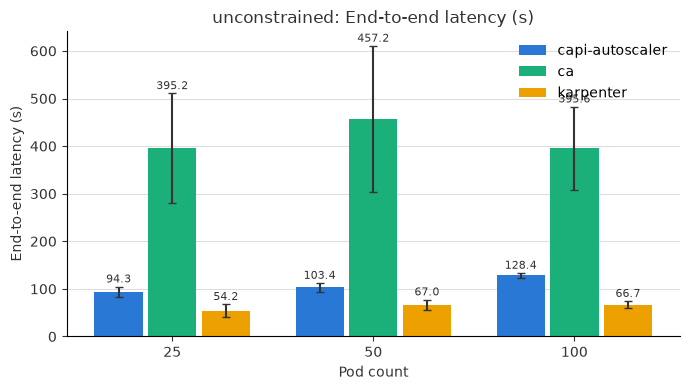

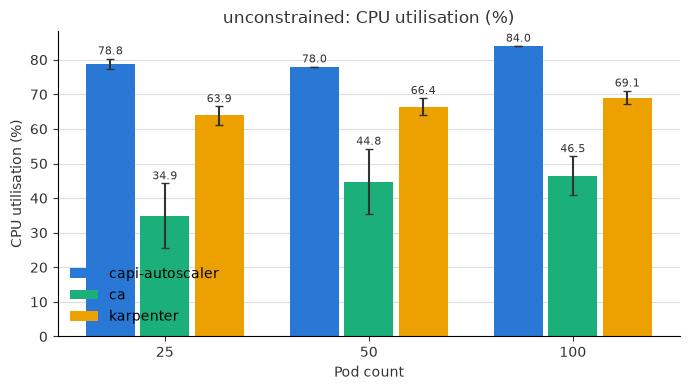

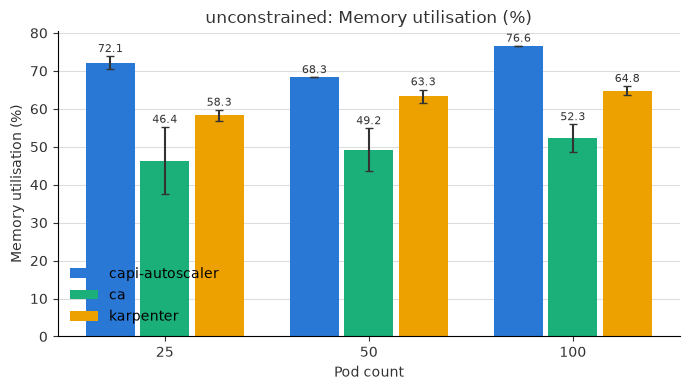

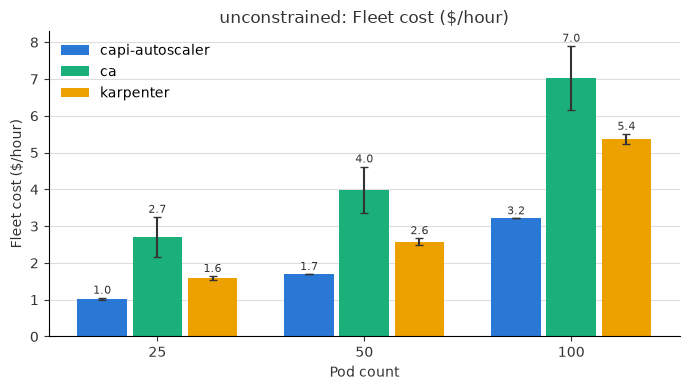

,autoscaler,pod_count,n_ok,n_total,n_timed_out,latency_s_mean,latency_s_ci95,first_unschedulable_s_mean,first_unschedulable_s_ci95,all_scheduled_s_mean,all_scheduled_s_ci95,worker_nodes_mean,worker_nodes_ci95,workload_cpu_util_pct_mean,workload_cpu_util_pct_ci95,workload_mem_util_pct_mean,workload_mem_util_pct_ci95,cost_per_hour_mean,cost_per_hour_ci95
0,capi-autoscaler,25,10,10,0,89.195210,7.206443,8.992496,NaN,89.195208,7.206444,7.0,0.000000,80.00,0.000000,20.10,0.000000,0.74420,0.000000
1,capi-autoscaler,50,10,10,0,99.237432,20.764117,107.552717,NaN,99.237430,20.764117,14.1,0.226216,79.62,0.859620,20.03,0.158351,1.49800,0.021717
2,capi-autoscaler,100,10,10,0,175.998559,29.582880,135.714609,17.288144,175.998557,29.582880,24.9,2.118069,82.53,1.361498,19.74,1.457176,3.06538,0.082638
3,cas,25,10,10,0,111.612922,17.134043,6.918024,1.741021,111.612919,17.134043,8.9,0.711372,57.54,0.995349,26.97,0.713008,1.24640,0.021717
4,cas,50,10,10,0,108.655575,19.731611,6.648354,2.125094,108.655572,19.731610,15.7,0.757813,65.64,1.314389,29.34,0.742043,2.20600,0.045404
5,cas,100,10,10,0,156.673425,22.957416,9.589944,7.749328,156.673423,22.957416,29.0,1.877575,68.45,2.909753,31.84,1.408767,4.20112,0.183257
6,karpenter,25,10,10,0,63.406454,9.002618,5.500280,0.279840,63.406451,9.002618,7.8,0.564281,73.08,4.385682,33.80,2.495218,1.00804,0.075796
7,karpenter,50,10,10,0,75.395519,11.902801,5.440172,0.025559,75.395516,11.902801,13.8,0.941811,76.10,3.070577,34.74,3.339899,1.94850,0.075429
8,karpenter,100,10,10,0,82.654171,4.322520,7.250702,3.325327,82.654168,4.322520,28.1,1.734320,75.51,2.708392,33.41,2.430682,3.93900,0.143052


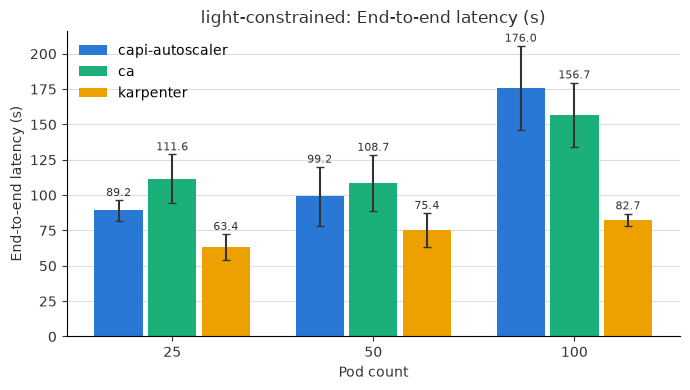

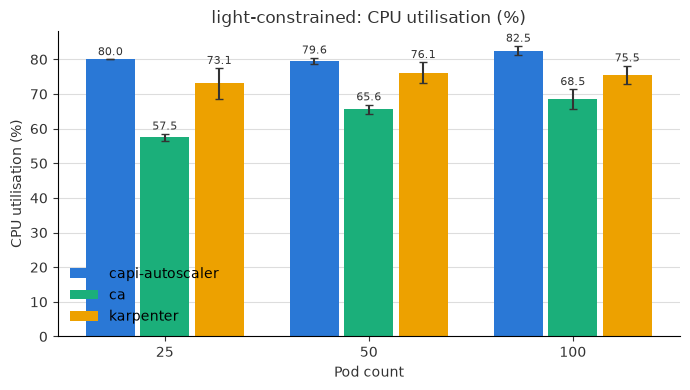

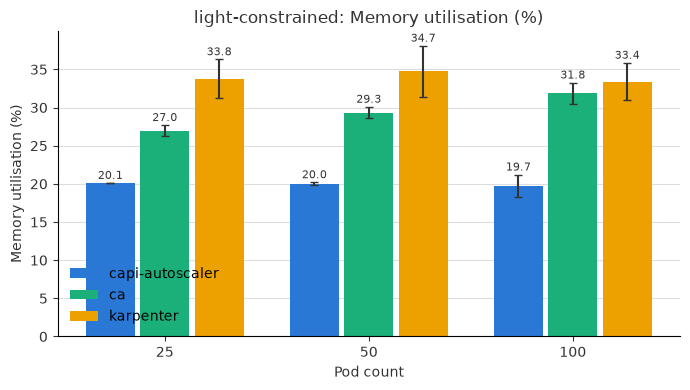

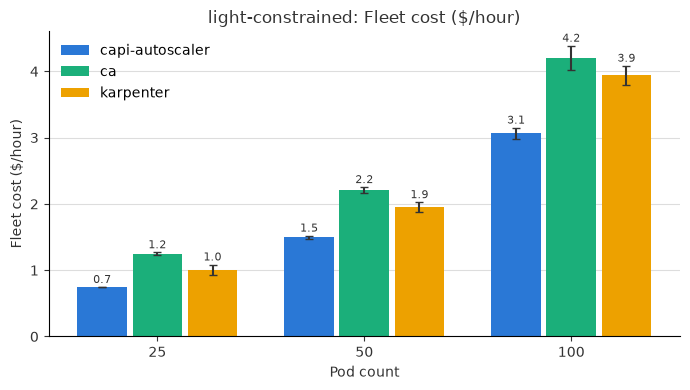

,autoscaler,pod_count,n_ok,n_total,n_timed_out,latency_s_mean,latency_s_ci95,first_unschedulable_s_mean,first_unschedulable_s_ci95,all_scheduled_s_mean,all_scheduled_s_ci95,worker_nodes_mean,worker_nodes_ci95,workload_cpu_util_pct_mean,workload_cpu_util_pct_ci95,workload_mem_util_pct_mean,workload_mem_util_pct_ci95,cost_per_hour_mean,cost_per_hour_ci95
0,capi-autoscaler,25,10,10,0,107.873206,30.583568,85.514745,45.341636,107.873203,30.583568,7.400,0.369409,76.860,2.438098,71.30,1.477635,1.047400,0.035463
1,capi-autoscaler,50,10,10,0,91.895645,17.595302,65.403179,22.539568,91.895643,17.595302,13.100,0.226216,81.510,0.882241,75.16,0.542918,1.775600,0.021717
2,capi-autoscaler,100,10,10,0,140.168642,27.402326,117.266536,9.633668,140.168640,27.402326,26.600,0.603242,80.720,1.180182,74.68,0.723890,3.589600,0.057911
3,cas,25,10,10,0,384.435824,116.545556,6.140483,1.556359,384.435822,116.545555,18.100,2.769539,33.980,7.232601,42.31,5.308491,2.742720,0.469988
4,cas,50,10,10,0,266.498956,112.565649,5.987533,0.871030,266.498954,112.565649,26.600,5.105330,45.760,8.378347,48.73,5.401147,3.685580,0.779994
5,cas,100,8,10,2,446.967208,63.585297,5.708245,0.230699,446.967206,63.585297,60.375,5.910505,32.675,5.934276,42.10,3.588357,9.927025,1.382701
6,karpenter,25,10,10,0,61.172711,10.068498,5.439616,0.105901,61.172708,10.068498,10.300,1.014474,55.330,3.358548,52.94,2.046860,1.350800,0.097389
7,karpenter,50,10,10,0,74.223150,10.035121,6.214092,1.413451,74.223148,10.035121,19.200,1.000364,60.050,3.233689,59.17,4.144552,2.399300,0.124279
8,karpenter,100,10,10,0,80.462738,9.034098,7.340015,2.682299,80.462734,9.034099,38.200,2.231791,59.390,2.397709,57.68,1.813116,4.831200,0.229716


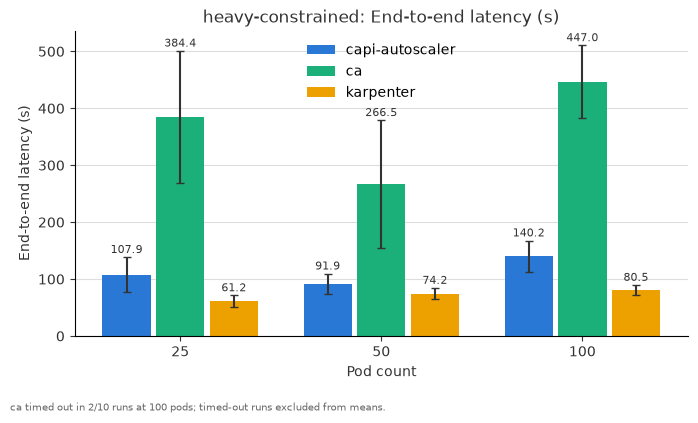

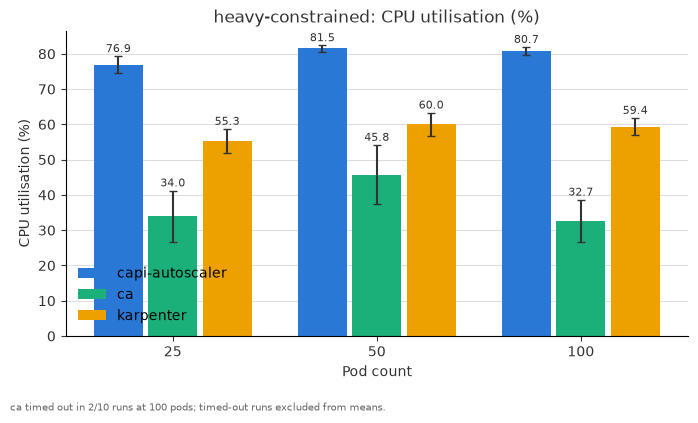

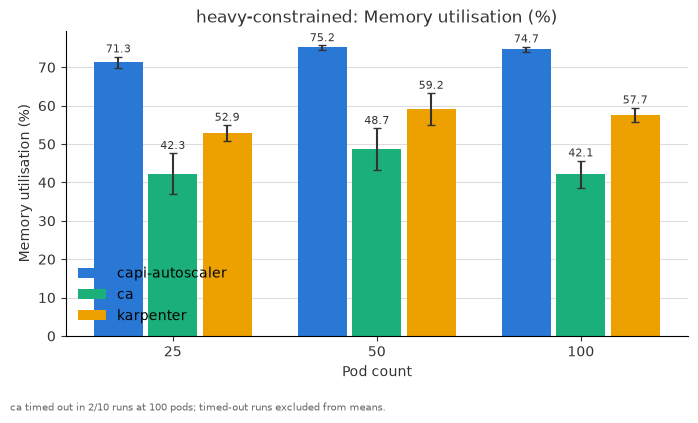

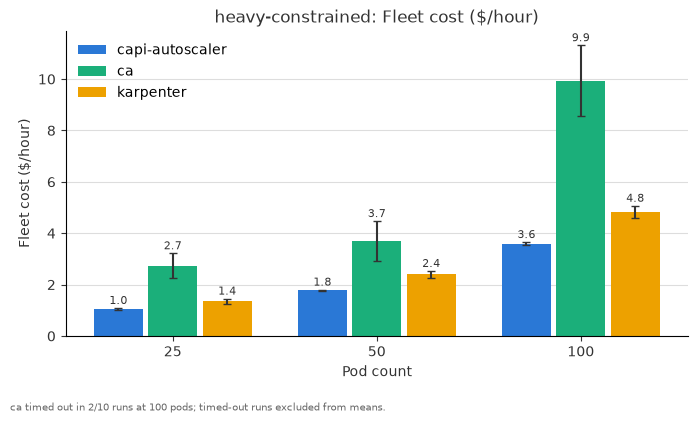

In [4]:
RQ1_METRICS = ["latency_s", "first_unschedulable_s", "all_scheduled_s",
               "worker_nodes", "workload_cpu_util_pct", "workload_mem_util_pct", "cost_per_hour"]
CHART_METRICS = ["latency_s", "workload_cpu_util_pct", "workload_mem_util_pct", "cost_per_hour"]


def timeout_note(table):
    parts = [f"{plotting.display_name(r.autoscaler)} timed out in {r.n_timed_out}/{r.n_total} runs at {r.pod_count} pods"
             for r in table.itertuples() if r.n_timed_out > 0]
    if not parts:
        return ""
    return "; ".join(parts) + "; timed-out runs excluded from means."


scores = {}
for profile in config.PROFILES:
    prof_df = main[main["profile"] == profile]
    if prof_df.empty:
        print(summaries.no_data_note(f"profile {profile}",
              "No runs in the loaded batches; re-run benchmarks for this profile."))
        continue
    table = stats.score_table(prof_df, ["autoscaler", "pod_count"], RQ1_METRICS)
    scores[profile] = table
    export.save_table(table, f"rq1_scores_{profile}")
    display(table)
    note = timeout_note(table)
    for metric in CHART_METRICS:
        if table[f"{metric}_mean"].notna().any():
            fig = plotting.comparison_bars(table, metric, f"{profile}: {plotting.METRIC_LABELS[metric]}")
            if note:
                plotting.add_footnote(fig, note)
            export.save_figure(fig, f"rq1_{profile}_{metric}")
            plt.show()

In [5]:
# 100-pod feasibility: non-timed-out fraction per autoscaler
big = main[main["pod_count"] == 100]
if big.empty:
    print(summaries.no_data_note("100-pod feasibility", "No 100-pod runs loaded."))
else:
    feasibility = (big.groupby(["profile", "autoscaler"])
        .agg(ok_runs=("timed_out", lambda s: int((~s).sum())), total_runs=("timed_out", "count"),
             mean_latency_s=("latency_s", "mean"))
        .reset_index())
    export.save_table(feasibility, "rq1_feasibility_100pods")
    display(feasibility)

,profile,autoscaler,ok_runs,total_runs,mean_latency_s
0,heavy-constrained,capi-autoscaler,10,10,140.168642
1,heavy-constrained,cas,8,10,446.967208
2,heavy-constrained,karpenter,10,10,80.462738
3,light-constrained,capi-autoscaler,10,10,175.998559
4,light-constrained,cas,10,10,156.673425
5,light-constrained,karpenter,10,10,82.654171
6,unconstrained,capi-autoscaler,10,10,128.375230
7,unconstrained,cas,10,10,395.597824
8,unconstrained,karpenter,10,10,66.739908


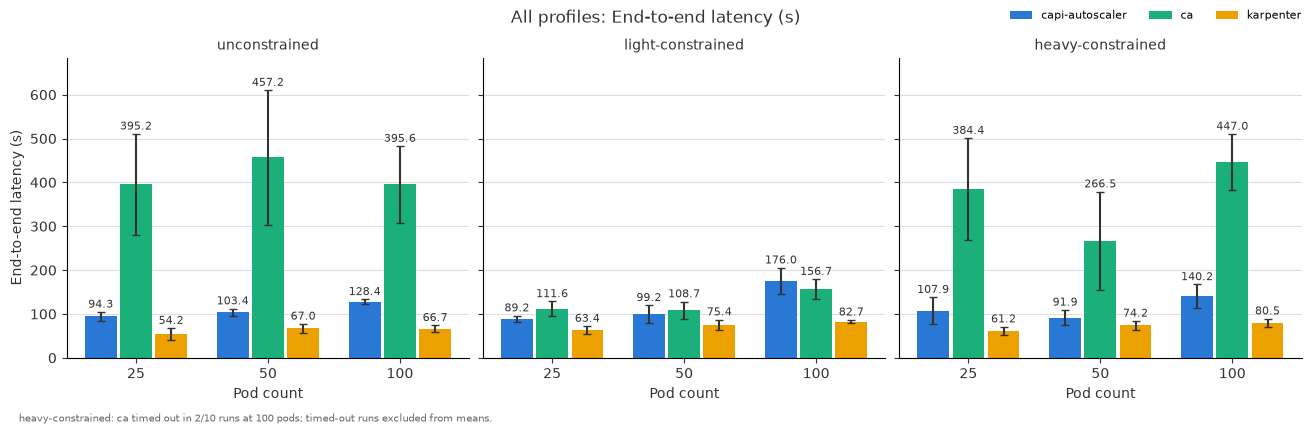

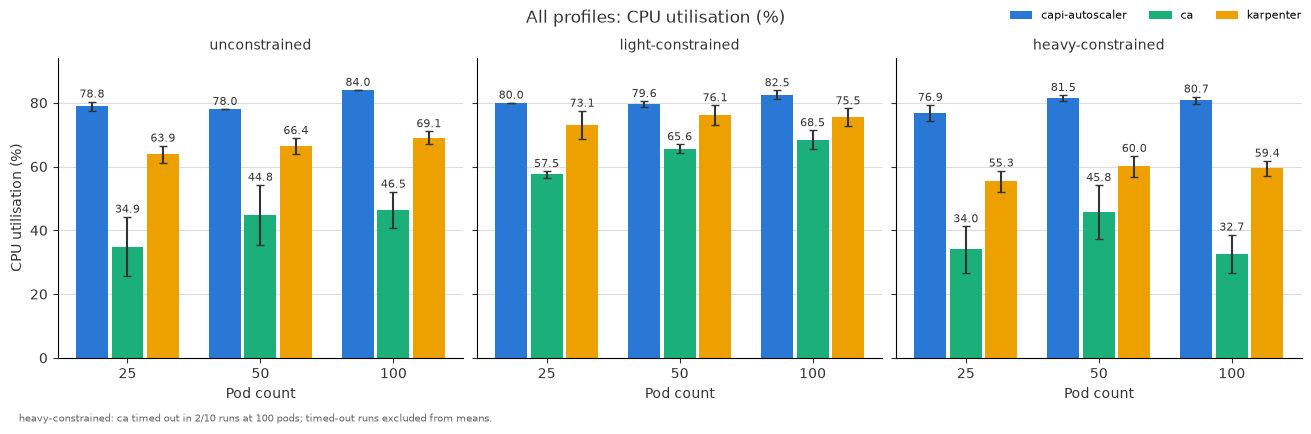

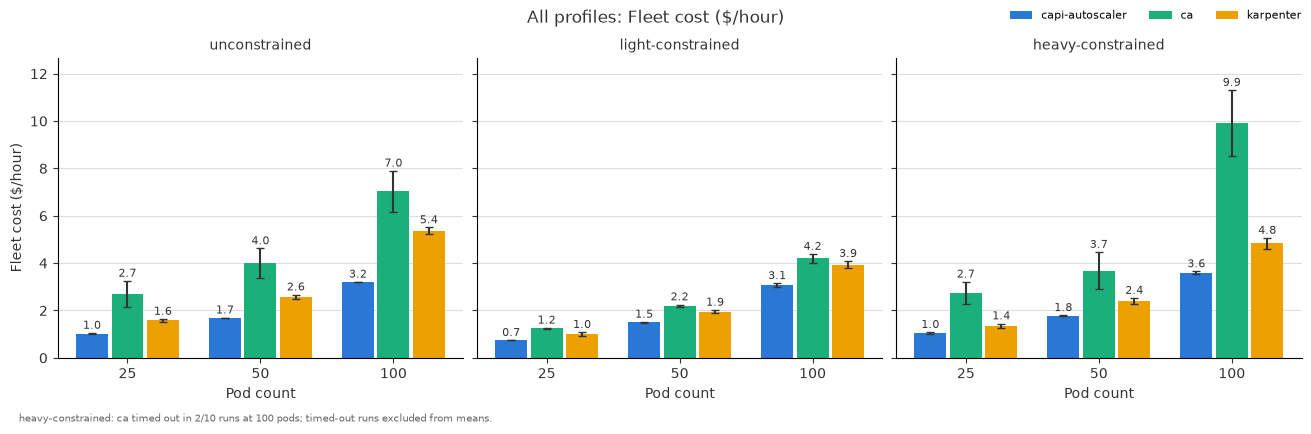

In [6]:
# Composite: latency, CPU utilisation and fleet cost across all three
# profiles, one 3-panel figure per metric, so the report needs one figure not three.
for metric in ("latency_s", "workload_cpu_util_pct", "cost_per_hour"):
    tables = {p: t for p, t in scores.items() if t[f"{metric}_mean"].notna().any()}
    if not tables:
        print(summaries.no_data_note(f"RQ1 composite {metric}", "No score tables loaded."))
        continue
    fig = plotting.comparison_bars_composite(
        tables, metric, f"All profiles: {plotting.METRIC_LABELS[metric]}")
    note = "; ".join(f"{p}: {timeout_note(t)}" for p, t in tables.items() if timeout_note(t))
    if note:
        plotting.add_footnote(fig, note)
    export.save_figure(fig, f"rq1_composite_{metric}")
    plt.show()

## RQ2: solver scalability

Solve time and quality as pod count grows, from the `*_solver.csv` files the
harness writes on capi-autoscaler runs. Placementcontrol-cohort runs only.

,pod_count,solves,mean_solve_time_s,max_solve_time_s,unplaced,beam_solves
0,25,40,0.613000,2.53,0,0
1,50,34,7.530294,30.80,0,0
2,100,58,14.057414,30.28,0,0


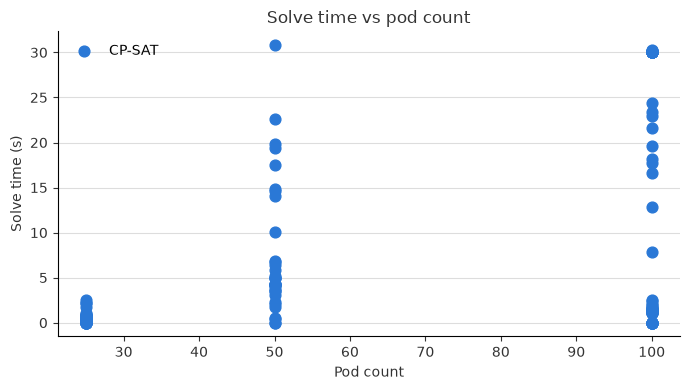

In [7]:
main_solver = solver[solver["run_id"].isin(main_ids)]
if main_solver.empty:
    print(summaries.no_data_note("RQ2",
          "No solver metrics captured yet; re-run capi benchmarks now the harness records them."))
else:
    solver_table = (main_solver.merge(main[["run_id", "pod_count"]], on="run_id")
        .groupby("pod_count")
        .agg(solves=("attempt", "count"), mean_solve_time_s=("solve_time_secs", "mean"),
             max_solve_time_s=("solve_time_secs", "max"), unplaced=("unplaced", "sum"),
             beam_solves=("used_beam", "sum"))
        .reset_index())
    export.save_table(solver_table, "rq2_solver_scaling")
    display(solver_table)
    fig = plotting.solver_scaling(main_solver, main, "Solve time vs pod count")
    export.save_figure(fig, "rq2_solve_time_vs_pods")
    plt.show()

### Offline: solver scaling across pods, MDs and slots

Factorial sweep from `make solver-bench-rq2` (benchmarks/solver-bench): pods x
MachineDeployment count x candidate slots per profile, under the production
CP-SAT config on instances mirroring the cluster pools and workload templates.
Answers the parts of RQ2 the cluster runs only vary by pod count.
`wall_time_secs` is timed around `optimise_placement`; unplaced pods mark
cells where the slot ceiling binds (the deliberate low-slots feasibility axis).

,profile,pod_count,md_count,slots_level,solves,mean_wall_s,max_wall_s,fully_placed_frac,mean_unplaced,proven_optimal,mean_gap_pct,max_gap_pct,mean_cost_per_hour
0,heavy-constrained,25,5,high,3,0.154,0.175,1.0,0.0,3,0.000,0.000,1.034
1,heavy-constrained,25,5,low,3,0.042,0.047,1.0,0.0,3,0.000,0.000,1.034
2,heavy-constrained,25,5,med,3,0.066,0.079,1.0,0.0,3,0.000,0.000,1.034
3,heavy-constrained,25,10,high,3,0.765,1.004,1.0,0.0,3,0.000,0.000,0.883
4,heavy-constrained,25,10,low,3,0.131,0.157,1.0,0.0,3,0.000,0.000,0.883
...,...,...,...,...,...,...,...,...,...,...,...,...,...
76,unconstrained,100,10,low,3,19.395,30.196,0.0,6.0,2,NaN,NaN,2.680
77,unconstrained,100,10,med,3,30.108,30.133,1.0,0.0,0,46.070,50.874,2.825
78,unconstrained,100,15,high,3,31.334,32.380,1.0,0.0,0,57.185,62.933,2.825
79,unconstrained,100,15,low,3,30.796,31.525,0.0,6.0,0,NaN,NaN,2.680


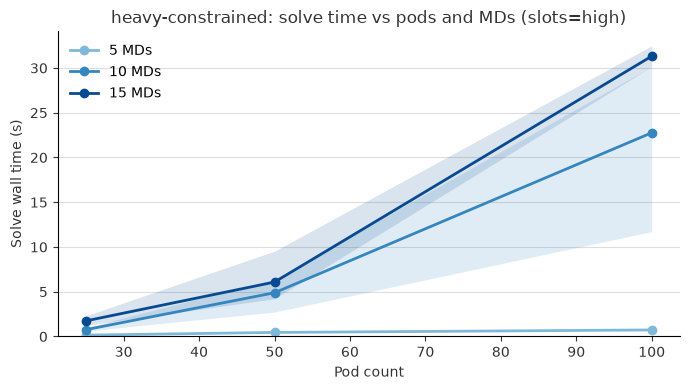

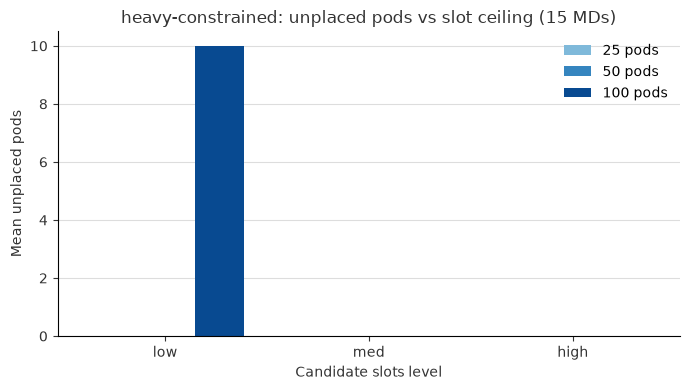

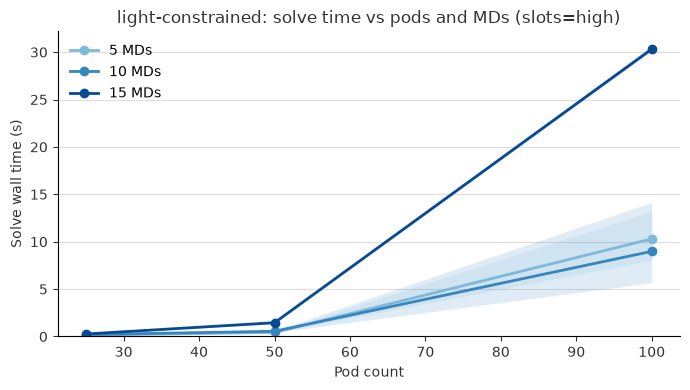

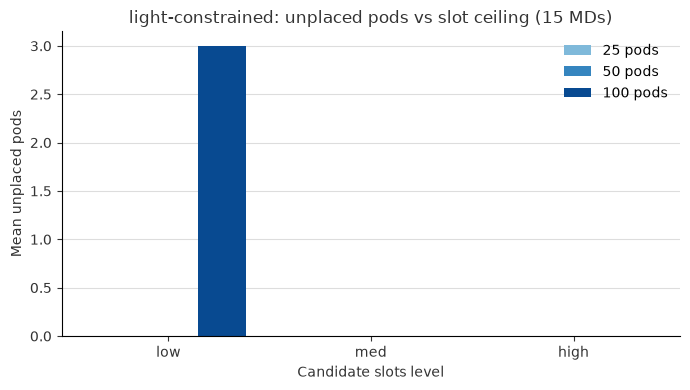

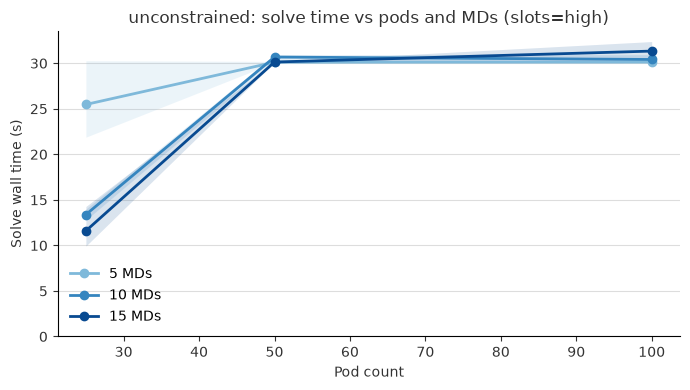

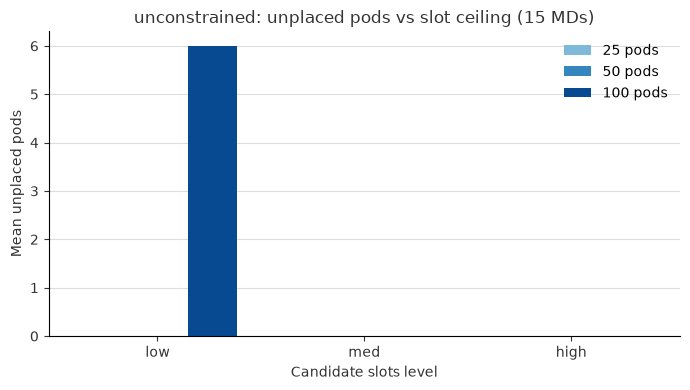

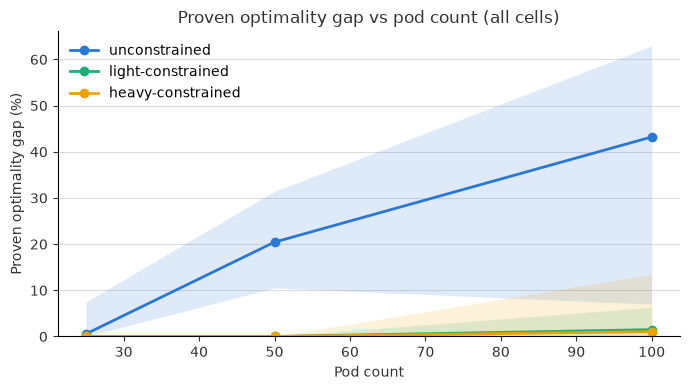

In [8]:
sb2 = loading.load_solver_bench("rq2")
if sb2.empty:
    print(summaries.no_data_note("RQ2 offline",
          "No solverbench rq2 CSVs; run make solver-bench-rq2."))
else:
    sb2 = sb2.assign(fully_placed=sb2["success"] & (sb2["unplaced_pods"] == 0))
    sb2["gap_pct"] = (sb2["optimality_gap"] * 100).where(sb2["fully_placed"])
    sb2_table = (sb2.groupby(["profile", "pod_count", "md_count", "slots_level"])
        .agg(solves=("rep", "count"),
             mean_wall_s=("wall_time_secs", "mean"), max_wall_s=("wall_time_secs", "max"),
             fully_placed_frac=("fully_placed", "mean"), mean_unplaced=("unplaced_pods", "mean"),
             proven_optimal=("status", lambda s: int((s == "Optimal").sum())),
             mean_gap_pct=("gap_pct", "mean"), max_gap_pct=("gap_pct", "max"),
             mean_cost_per_hour=("cost_per_hour", "mean"))
        .round(3).reset_index())
    export.save_table(sb2_table, "rq2b_offline_solver_scaling")
    display(sb2_table)
    for profile in sorted(sb2["profile"].unique()):
        high = sb2[(sb2["profile"] == profile) & (sb2["slots_level"] == "high")]
        fig = plotting.offline_scaling(high, f"{profile}: solve time vs pods and MDs (slots=high)")
        export.save_figure(fig, f"rq2b_{profile}_solve_time_scaling")
        plt.show()
        full = sb2[(sb2["profile"] == profile) & (sb2["md_count"] == sb2["md_count"].max())]
        fig = plotting.offline_feasibility(full, f"{profile}: unplaced pods vs slot ceiling (15 MDs)")
        export.save_figure(fig, f"rq2b_{profile}_feasibility")
        plt.show()

    fig = plotting.offline_gap(sb2, "Proven optimality gap vs pod count (all cells)")
    export.save_figure(fig, "rq2b_optimality_gap")
    plt.show()


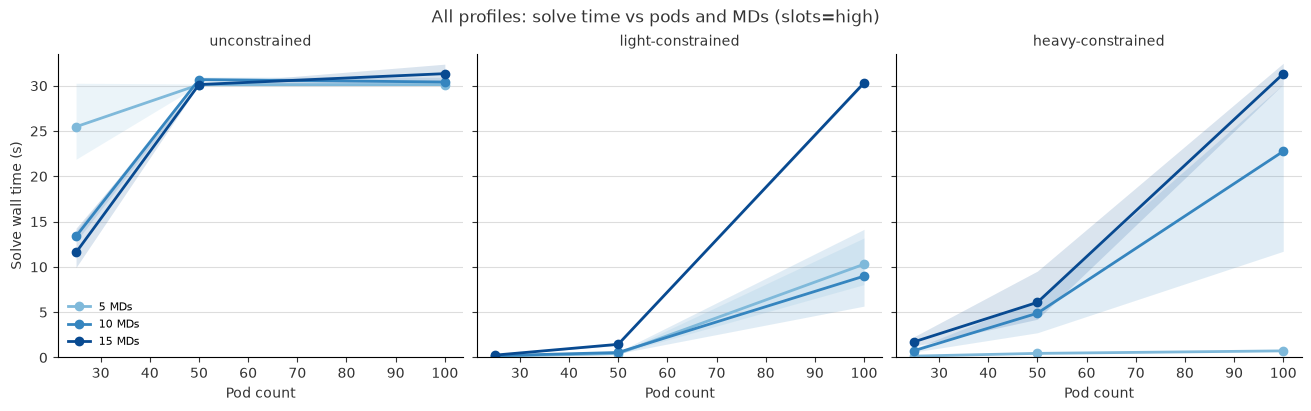

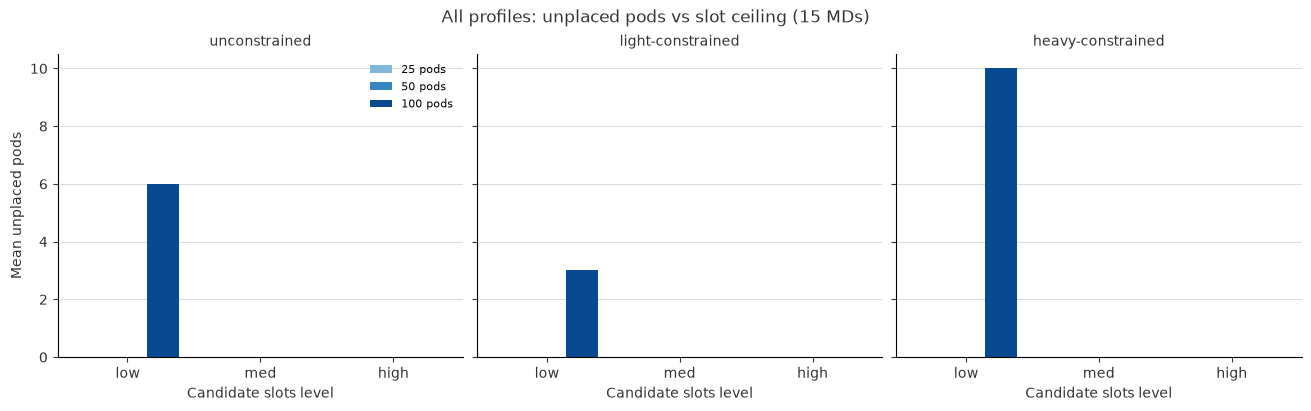

In [9]:
# Composite: solve-time scaling and slot-ceiling feasibility across all three
# profiles, one 3-panel figure each, same slices as the per-profile charts.
if sb2.empty:
    print(summaries.no_data_note("RQ2 offline composites",
          "No solverbench rq2 CSVs; run make solver-bench-rq2."))
else:
    profiles = sorted(sb2["profile"].unique())
    panels = {p: sb2[(sb2["profile"] == p) & (sb2["slots_level"] == "high")]
              for p in profiles}
    fig = plotting.offline_scaling_composite(
        panels, "All profiles: solve time vs pods and MDs (slots=high)")
    export.save_figure(fig, "rq2b_composite_solve_time_scaling")
    plt.show()
    md_max = sb2["md_count"].max()
    panels = {p: sb2[(sb2["profile"] == p) & (sb2["md_count"] == md_max)]
              for p in profiles}
    fig = plotting.offline_feasibility_composite(
        panels, f"All profiles: unplaced pods vs slot ceiling ({md_max} MDs)")
    export.save_figure(fig, "rq2b_composite_feasibility")
    plt.show()

## RQ3: beam-search fallback quality

Splits solves by `used_beam` and joins back to run outcomes, so beam-fallback
runs can be compared with CP-SAT runs on utilisation and cost.
Placementcontrol-cohort runs only.

In [10]:
if main_solver.empty or not main_solver["used_beam"].any():
    print(summaries.no_data_note("RQ3",
          "No beam-fallback solves recorded yet; needs runs where CP-SAT hits its time budget."))
else:
    beam_runs = main_solver.groupby("run_id")["used_beam"].any().rename("used_beam_run")
    joined = main.merge(beam_runs, on="run_id", how="inner")
    beam_table = (joined.groupby("used_beam_run")
        [["latency_s", "workload_cpu_util_pct", "workload_mem_util_pct", "cost_per_hour"]]
        .mean().round(2).reset_index())
    export.save_table(beam_table, "rq3_beam_vs_cpsat")
    display(beam_table)

**No data yet for RQ3.** No beam-fallback solves recorded yet; needs runs where CP-SAT hits its time budget.


### Offline: beam vs CP-SAT quality ladder

Identical instances through beam-only and single-attempt CP-SAT at 1/2/10/30 s
budgets (`make solver-bench-rq3`), quantifying the quality the bounded beam
heuristic gives up for near-zero runtime. Answers RQ3 directly even though the
in-cluster fallback never fires. `gap_pct` is the relative objective gap to
the best fully-placed solution for the same instance; rows with unplaced pods
have no gap and count against `fully_placed_frac` instead.

,arm,profile,pod_count,solves,fully_placed_frac,mean_gap_pct,mean_unplaced,mean_wall_s,mean_cost_per_hour
0,beam,heavy-constrained,25,3,1.000,50.894,0.000,0.007,1.308
1,beam,heavy-constrained,50,3,1.000,54.805,0.000,0.002,2.490
2,beam,heavy-constrained,100,3,0.000,NaN,3.000,0.004,4.638
3,beam,light-constrained,25,3,1.000,16.118,0.000,0.002,0.766
4,beam,light-constrained,50,3,1.000,31.224,0.000,0.001,1.736
5,beam,light-constrained,100,3,1.000,23.889,0.000,0.002,3.206
6,beam,unconstrained,25,3,1.000,33.541,0.000,0.001,1.110
7,beam,unconstrained,50,3,1.000,34.481,0.000,0.001,2.064
8,beam,unconstrained,100,3,1.000,46.237,0.000,0.001,4.074
9,cpsat-1,heavy-constrained,25,3,1.000,23.253,0.000,1.031,1.085


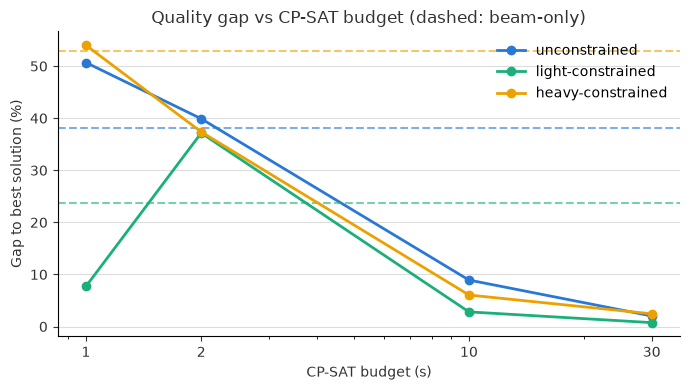

In [11]:
sb3 = loading.load_solver_bench("rq3")
if sb3.empty:
    print(summaries.no_data_note("RQ3 offline",
          "No solverbench rq3 CSVs; run make solver-bench-rq3."))
else:
    sb3 = sb3.assign(fully_placed=sb3["success"] & (sb3["unplaced_pods"] == 0))
    sb3["gap_pct"] = stats.relative_gap(sb3)
    sb3_table = (sb3.groupby(["arm", "profile", "pod_count"])
        .agg(solves=("rep", "count"), fully_placed_frac=("fully_placed", "mean"),
             mean_gap_pct=("gap_pct", "mean"), mean_unplaced=("unplaced_pods", "mean"),
             mean_wall_s=("wall_time_secs", "mean"), mean_cost_per_hour=("cost_per_hour", "mean"))
        .round(3).reset_index())
    export.save_table(sb3_table, "rq3b_beam_quality_ladder")
    display(sb3_table)
    fig = plotting.budget_quality(sb3, "Quality gap vs CP-SAT budget (dashed: beam-only)")
    export.save_figure(fig, "rq3b_quality_vs_budget")
    plt.show()

## RQ4: placement-aware vs provision-only utilisation

Two comparisons:

1. capi-autoscaler (placementcontrol) vs the provision-only baselines, cas and
   Karpenter. Provisioning efficiency is requested/allocatable at each run's
   steady state, non-timed-out runs only; the overlays show the scale-up
   trajectory and include timed-out runs, flagged per chart.
2. capi pre vs post placementcontrol: same solver, placement control is the
   only difference, so it is the cleanest placement-aware vs provision-only
   pair.

,scenario,autoscaler,ok_runs,total_runs,cpu_efficiency,mem_efficiency
0,heavy-constrained-100,capi-autoscaler,10,10,0.807,0.747
1,heavy-constrained-100,cas,8,10,0.327,0.421
2,heavy-constrained-100,karpenter,10,10,0.594,0.577
3,heavy-constrained-25,capi-autoscaler,10,10,0.769,0.713
4,heavy-constrained-25,cas,10,10,0.340,0.423
5,heavy-constrained-25,karpenter,10,10,0.553,0.530
6,heavy-constrained-50,capi-autoscaler,10,10,0.815,0.751
7,heavy-constrained-50,cas,10,10,0.458,0.487
8,heavy-constrained-50,karpenter,10,10,0.601,0.592
9,light-constrained-100,capi-autoscaler,10,10,0.825,0.197


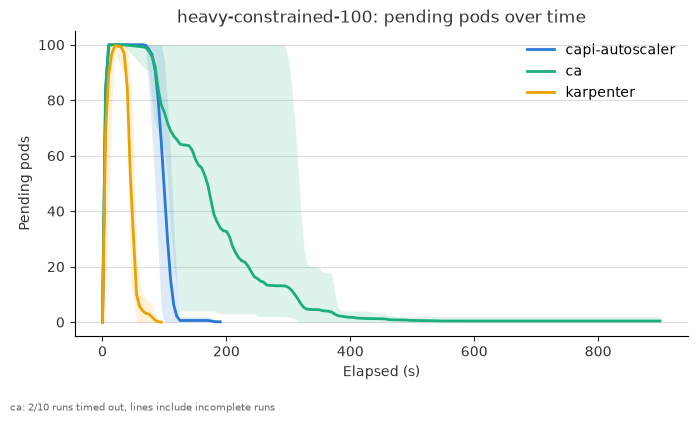

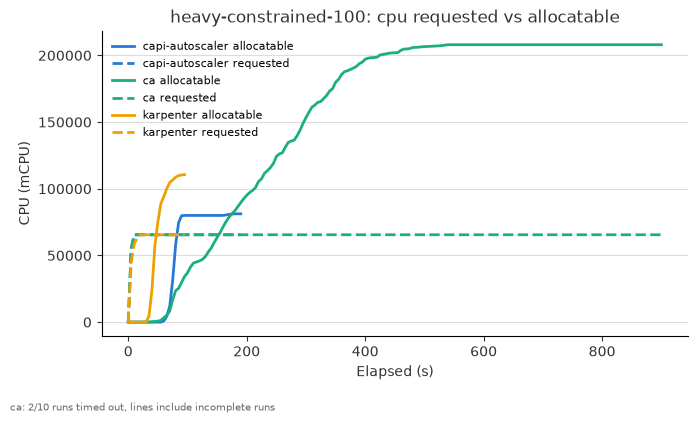

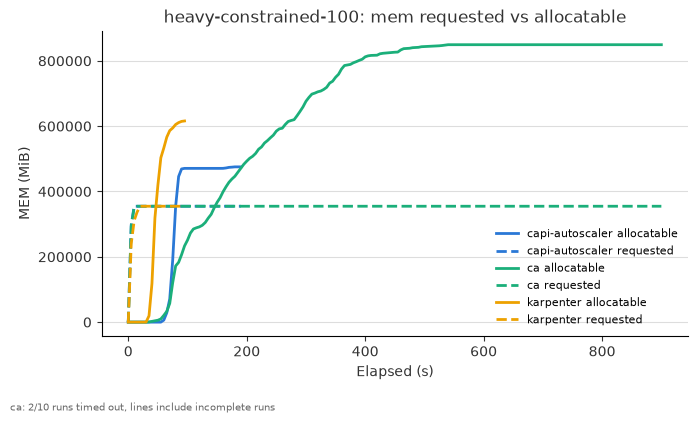

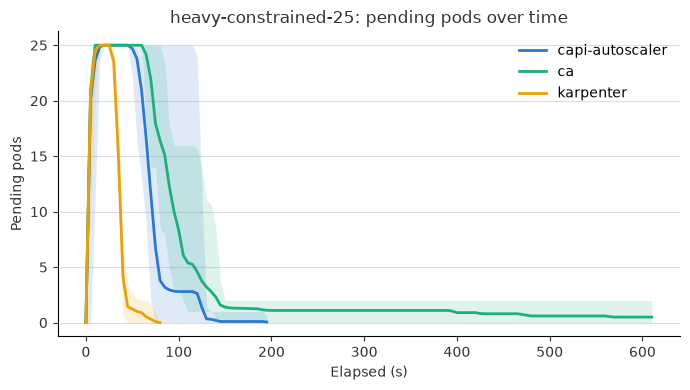

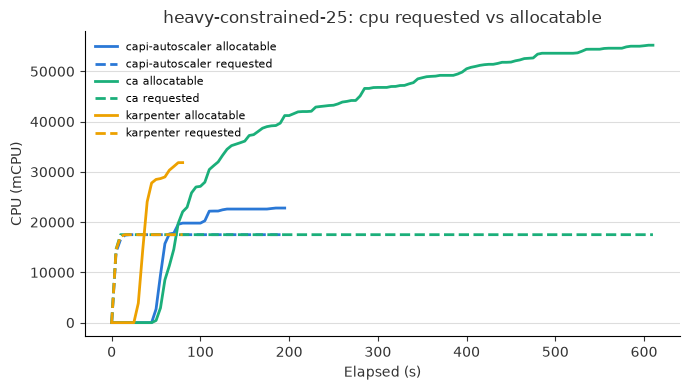

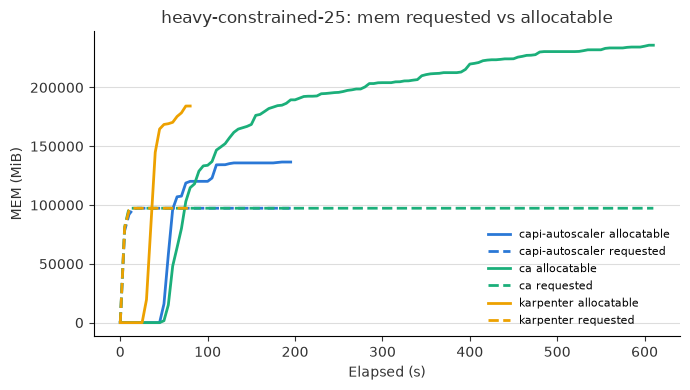

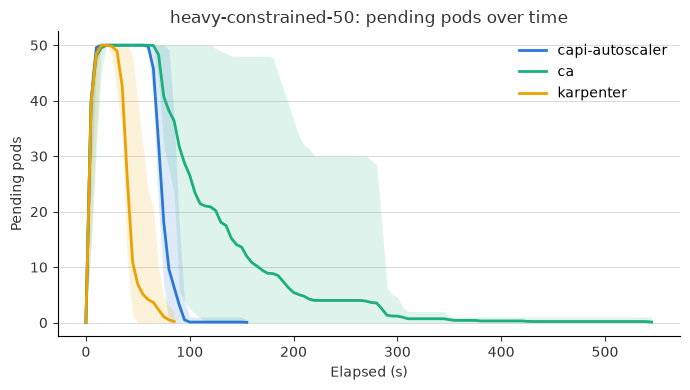

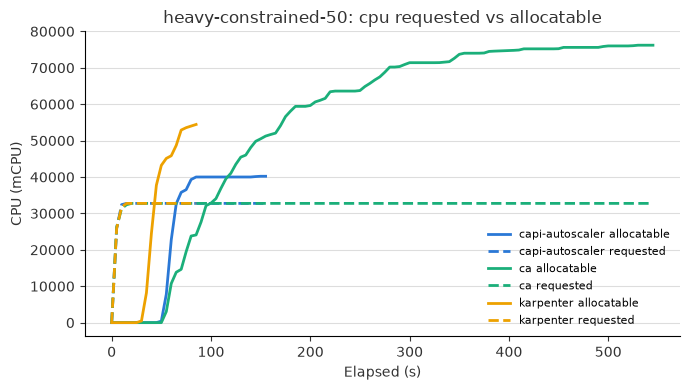

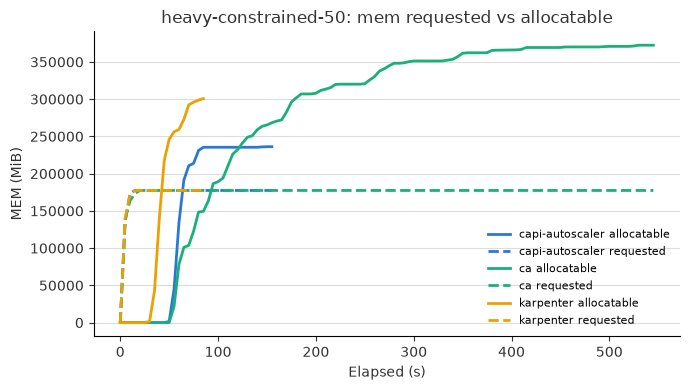

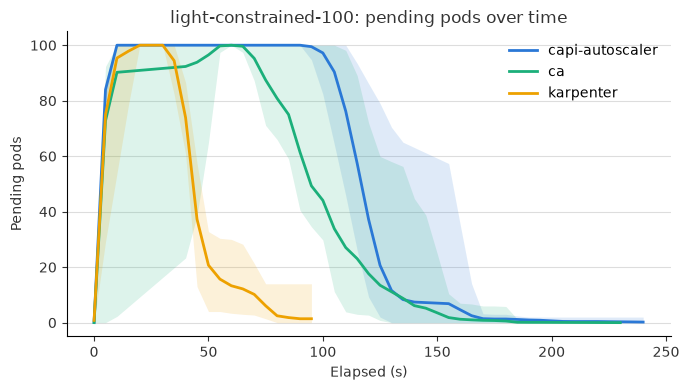

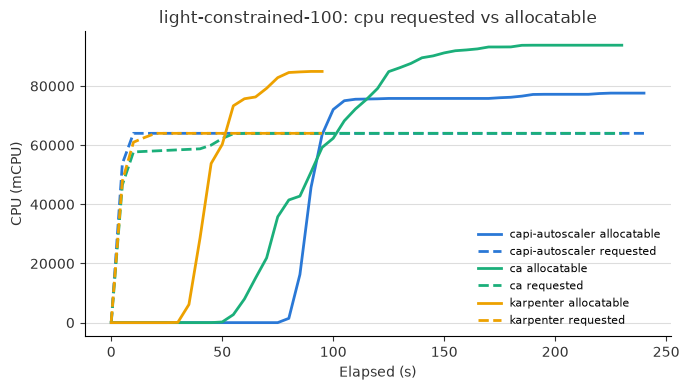

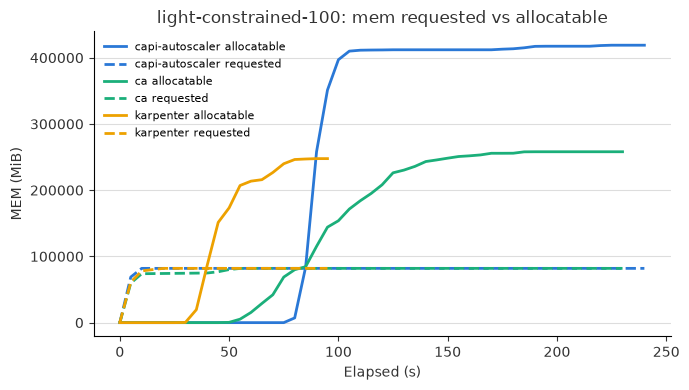

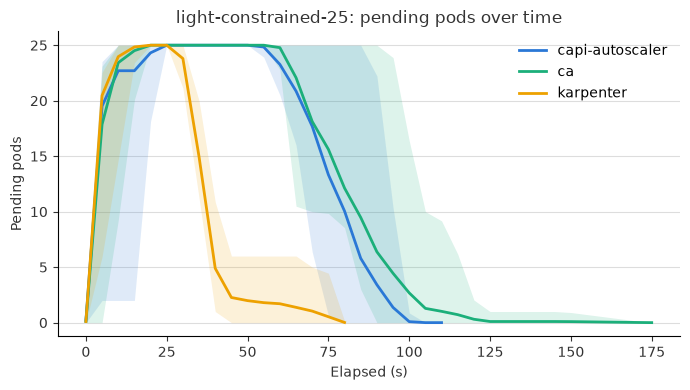

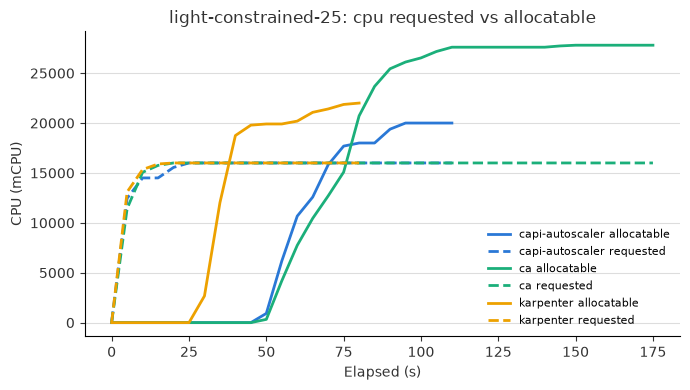

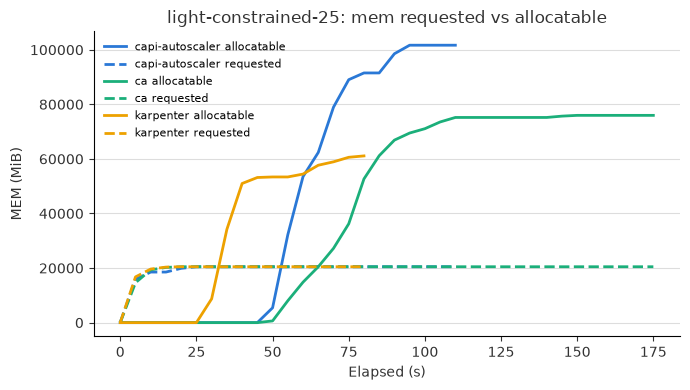

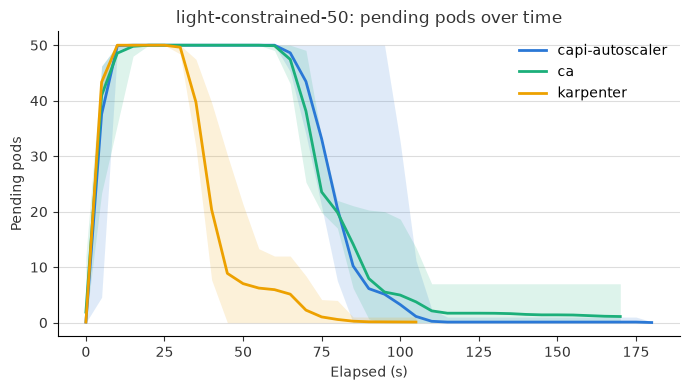

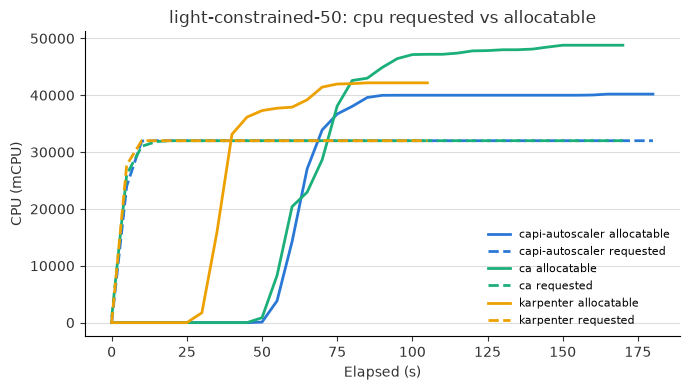

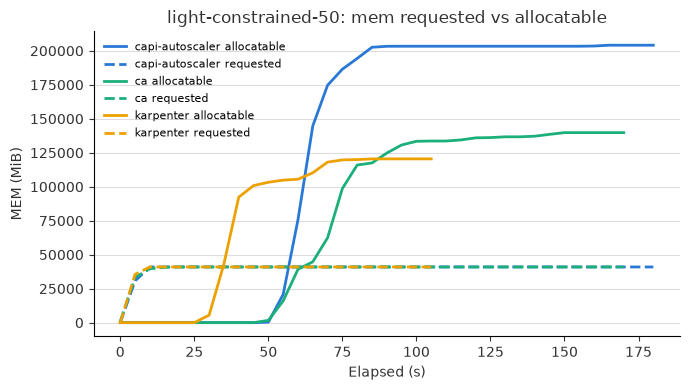

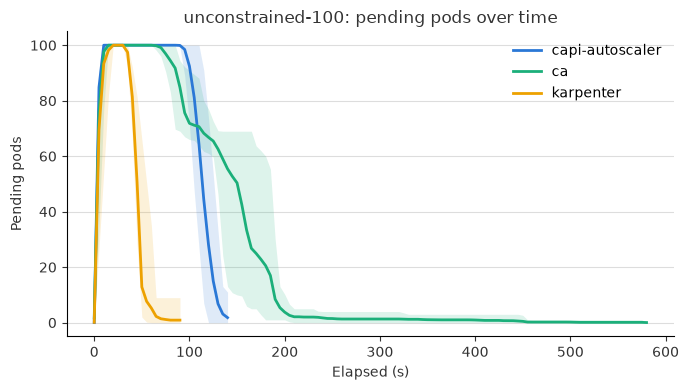

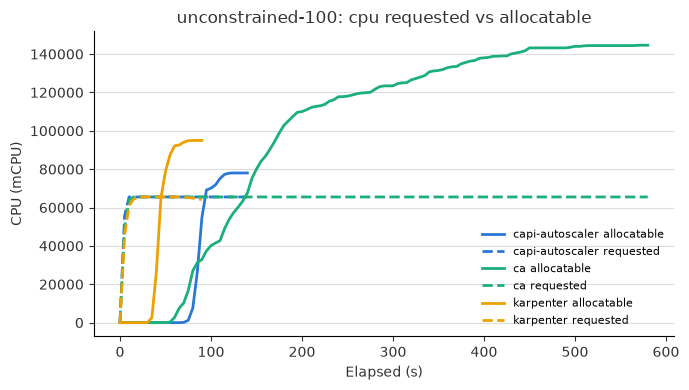

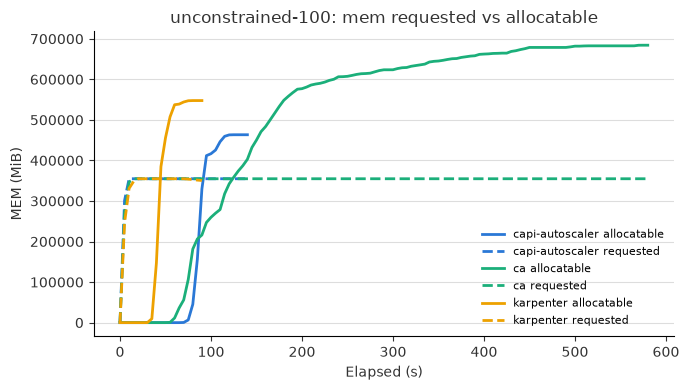

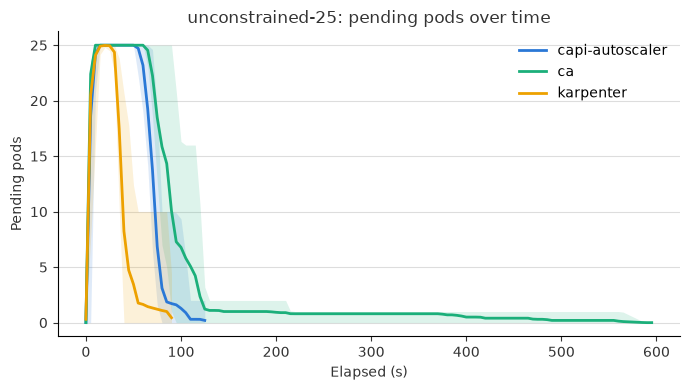

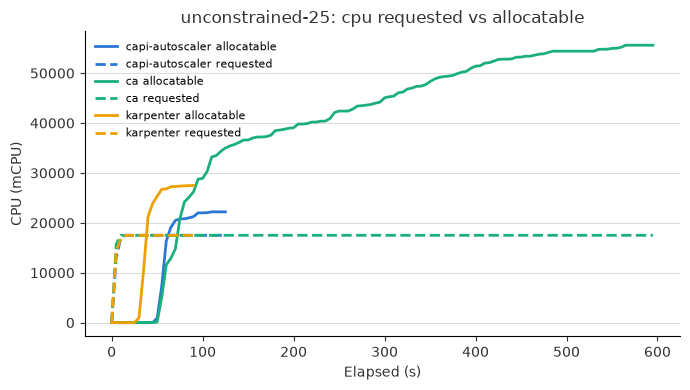

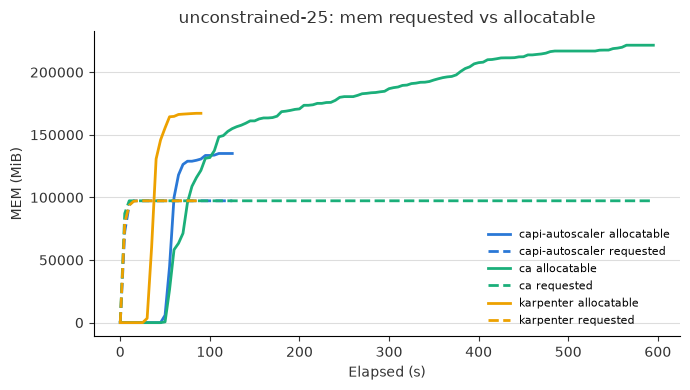

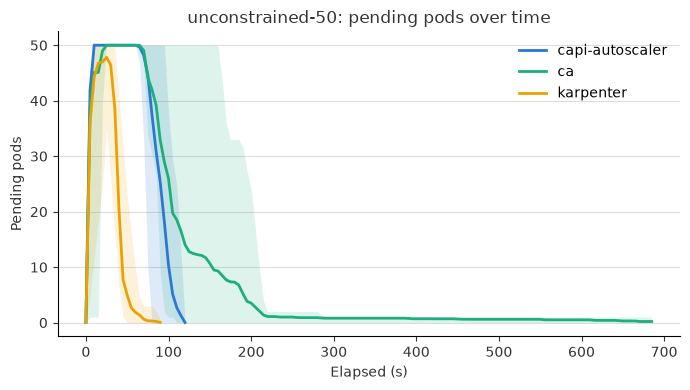

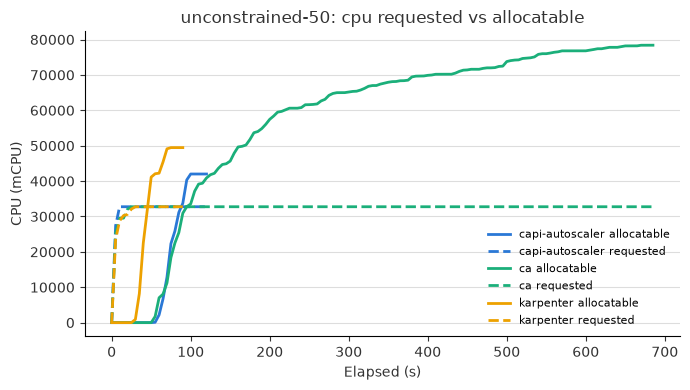

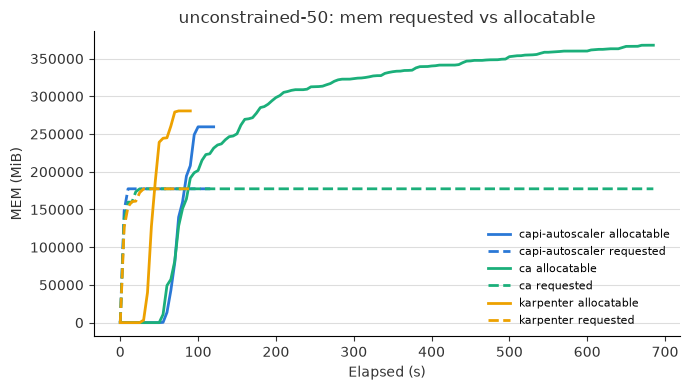

In [12]:
if timeseries.empty:
    print(summaries.no_data_note("RQ4", "No timeseries data loaded."))
else:
    main_ts = timeseries[timeseries["run_id"].isin(main_ids)]
    ok_ids = set(main.loc[~main["timed_out"], "run_id"])
    eff = stats.provisioning_efficiency(main_ts[main_ts["run_id"].isin(ok_ids)], main)
    counts = (main.groupby(["scenario", "autoscaler"])
        .agg(ok_runs=("timed_out", lambda s: int((~s).sum())),
             total_runs=("timed_out", "count")).reset_index())
    eff_summary = counts.merge(
        eff.groupby(["scenario", "autoscaler"])[["cpu_efficiency", "mem_efficiency"]]
        .mean().round(3).reset_index(),
        on=["scenario", "autoscaler"], how="left")
    export.save_table(eff_summary, "rq4_provisioning_efficiency")
    display(eff_summary)
    for scenario in sorted(main_ts["scenario"].unique()):
        t = (main[main["scenario"] == scenario].groupby("autoscaler")["timed_out"]
             .agg(["sum", "count"]))
        note = "; ".join(
            f"{plotting.display_name(a)}: {int(r['sum'])}/{int(r['count'])} runs timed out, lines include incomplete runs"
            for a, r in t.iterrows() if r["sum"] > 0)
        fig = plotting.timeseries_overlay(main_ts, "pending_pods", scenario,
                                          f"{scenario}: pending pods over time")
        if note:
            plotting.add_footnote(fig, note)
        export.save_figure(fig, f"rq4_{scenario}_pending_pods")
        plt.show()
        for resource in ("cpu", "mem"):
            fig = plotting.requested_vs_allocatable(main_ts, scenario, resource,
                    f"{scenario}: {resource} requested vs allocatable")
            if note:
                plotting.add_footnote(fig, note)
            export.save_figure(fig, f"rq4_{scenario}_{resource}_req_vs_alloc")
            plt.show()

### capi pre vs post placementcontrol

Same tables and bar charts as RQ1, then the same overlays as above, with the
two capi cohorts side by side. Post keeps the capi blue; pre is a lighter step
of the same hue.

,autoscaler,pod_count,n_ok,n_total,n_timed_out,latency_s_mean,latency_s_ci95,first_unschedulable_s_mean,first_unschedulable_s_ci95,all_scheduled_s_mean,all_scheduled_s_ci95,worker_nodes_mean,worker_nodes_ci95,workload_cpu_util_pct_mean,workload_cpu_util_pct_ci95,workload_mem_util_pct_mean,workload_mem_util_pct_ci95,cost_per_hour_mean,cost_per_hour_ci95
0,capi (placementcontrol),25,10,10,0,94.286758,10.530370,5.335189,0.437838,94.286755,10.530371,7.1,0.226216,78.84,1.493024,72.13,1.741861e+00,1.0216,2.850318e-02
1,capi (placementcontrol),50,10,10,0,103.421452,8.884194,NaN,NaN,103.421450,8.884194,12.0,0.000000,78.00,0.000000,68.30,1.071573e-14,1.6950,1.674333e-16
2,capi (placementcontrol),100,10,10,0,128.375230,5.148752,NaN,NaN,128.375227,5.148752,24.0,0.000000,84.00,0.000000,76.60,0.000000e+00,3.2090,3.348665e-16
3,capi (pre-placementcontrol),25,2,2,0,140.624965,312.886235,5.528097,0.712549,140.624963,312.886230,7.5,6.353102,76.20,41.930476,70.90,2.541241e+01,1.0570,6.098978e-01
4,capi (pre-placementcontrol),50,2,2,0,130.409385,464.870242,5.551929,1.383520,130.409382,464.870255,13.5,19.059307,73.10,62.260403,65.55,3.494206e+01,1.8390,1.829693e+00
5,capi (pre-placementcontrol),100,2,2,0,153.267240,59.855119,5.689400,1.206392,153.267236,59.855113,29.0,0.000000,73.60,10.164964,68.55,1.334151e+01,3.7820,8.004909e-01


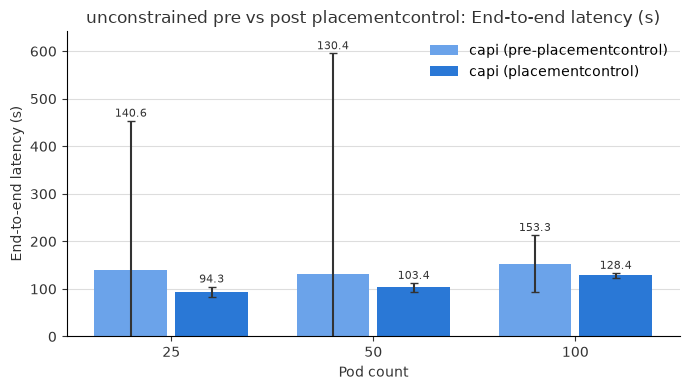

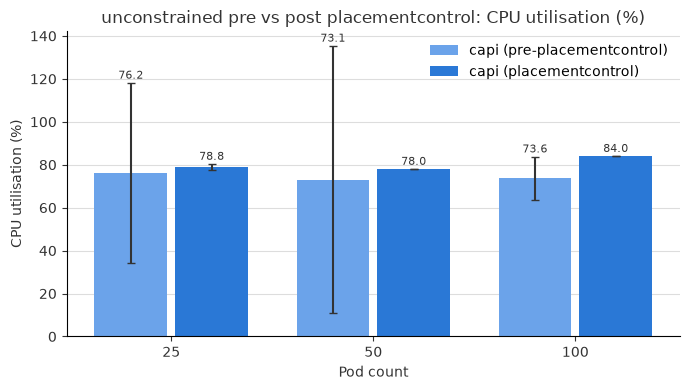

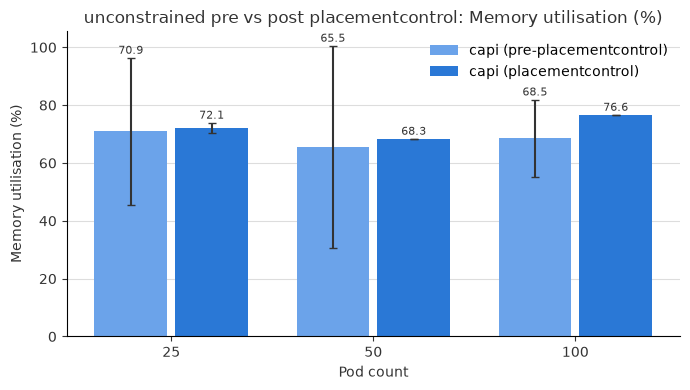

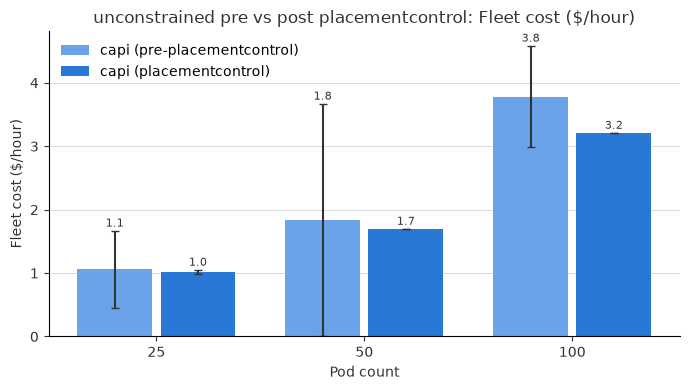

,autoscaler,pod_count,n_ok,n_total,n_timed_out,latency_s_mean,latency_s_ci95,first_unschedulable_s_mean,first_unschedulable_s_ci95,all_scheduled_s_mean,all_scheduled_s_ci95,worker_nodes_mean,worker_nodes_ci95,workload_cpu_util_pct_mean,workload_cpu_util_pct_ci95,workload_mem_util_pct_mean,workload_mem_util_pct_ci95,cost_per_hour_mean,cost_per_hour_ci95
0,capi (placementcontrol),25,10,10,0,89.195210,7.206443,8.992496,NaN,89.195208,7.206444,7.0,0.000000,80.00,0.000000,20.10,0.000000,0.74420,0.000000
1,capi (placementcontrol),50,10,10,0,99.237432,20.764117,107.552717,NaN,99.237430,20.764117,14.1,0.226216,79.62,0.859620,20.03,0.158351,1.49800,0.021717
2,capi (placementcontrol),100,10,10,0,175.998559,29.582880,135.714609,17.288144,175.998557,29.582880,24.9,2.118069,82.53,1.361498,19.74,1.457176,3.06538,0.082638
3,capi (pre-placementcontrol),25,2,2,0,136.957191,30.415238,5.486446,0.959998,136.957188,30.415225,8.5,6.353102,69.70,38.118614,18.10,7.623723,0.88820,0.609898
4,capi (pre-placementcontrol),50,2,2,0,173.567735,430.753719,5.761334,1.086266,173.567734,430.753719,21.0,38.118614,54.20,124.520806,14.00,44.471717,2.37840,5.489080
5,capi (pre-placementcontrol),100,2,2,0,170.650539,142.514804,5.832802,3.352016,170.650535,142.514819,31.5,44.471717,72.35,71.790057,18.55,8.259033,3.49560,2.195632


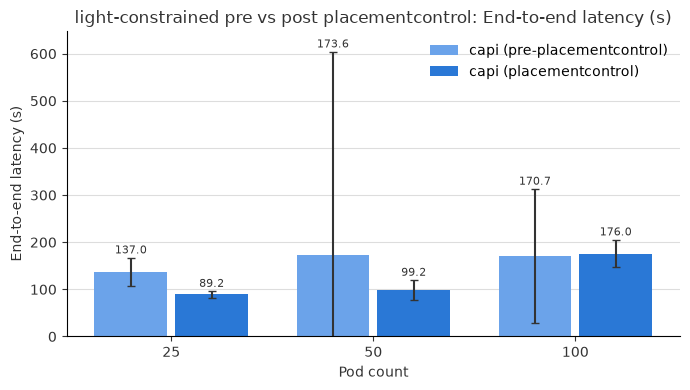

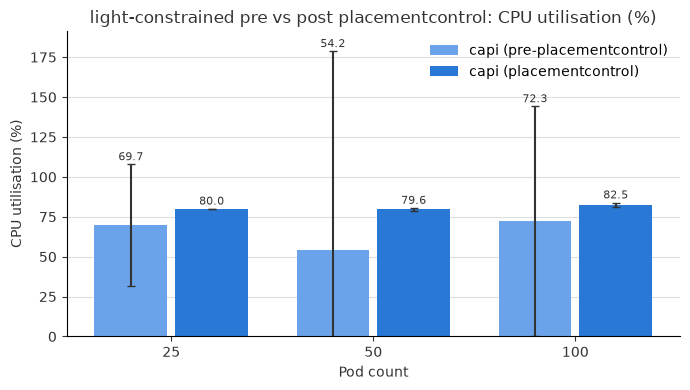

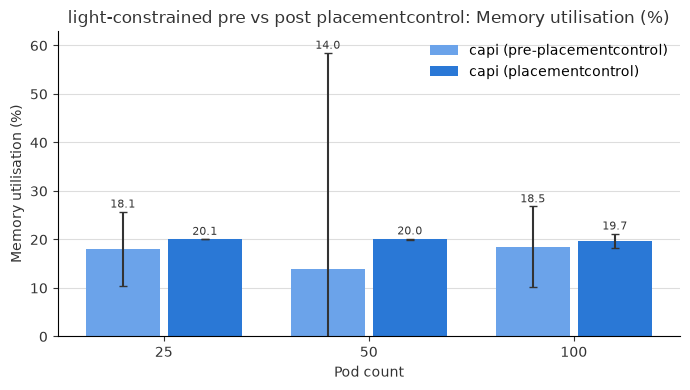

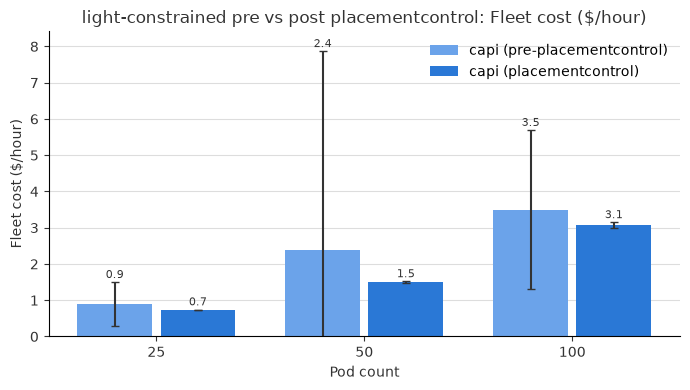

,autoscaler,pod_count,n_ok,n_total,n_timed_out,latency_s_mean,latency_s_ci95,first_unschedulable_s_mean,first_unschedulable_s_ci95,all_scheduled_s_mean,all_scheduled_s_ci95,worker_nodes_mean,worker_nodes_ci95,workload_cpu_util_pct_mean,workload_cpu_util_pct_ci95,workload_mem_util_pct_mean,workload_mem_util_pct_ci95,cost_per_hour_mean,cost_per_hour_ci95
0,capi (placementcontrol),25,10,10,0,107.873206,30.583568,85.514745,45.341636,107.873203,30.583568,7.4,0.369409,76.86,2.438098,71.30,1.477635,1.0474,0.035463
1,capi (placementcontrol),50,10,10,0,91.895645,17.595302,65.403179,22.539568,91.895643,17.595302,13.1,0.226216,81.51,0.882241,75.16,0.542918,1.7756,0.021717
2,capi (placementcontrol),100,10,10,0,140.168642,27.402326,117.266536,9.633668,140.168640,27.402326,26.6,0.603242,80.72,1.180182,74.68,0.723890,3.5896,0.057911
3,capi (pre-placementcontrol),25,2,2,0,155.055772,29.365731,24.160670,123.159053,155.055771,29.365732,11.5,31.765512,53.55,174.710315,50.90,184.239969,1.6095,5.190485
4,capi (pre-placementcontrol),50,2,2,0,140.898468,155.277980,5.549625,2.015808,140.898465,155.277976,15.5,6.353102,69.70,19.059307,63.70,11.435584,2.1620,0.609898
5,capi (pre-placementcontrol),100,2,2,0,149.440964,9.656081,5.732769,1.155280,149.440962,9.656089,33.5,19.059307,65.60,33.036132,60.40,30.494891,4.6420,2.820777


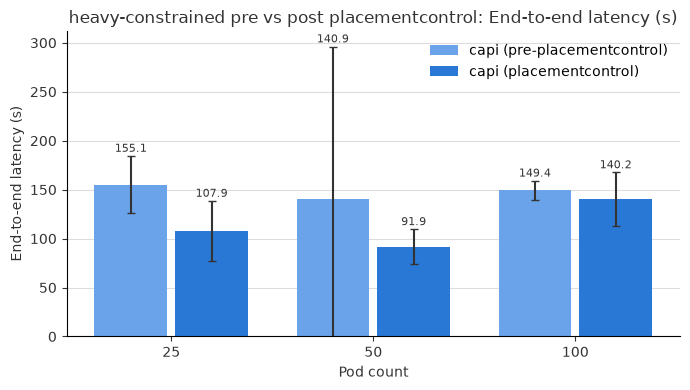

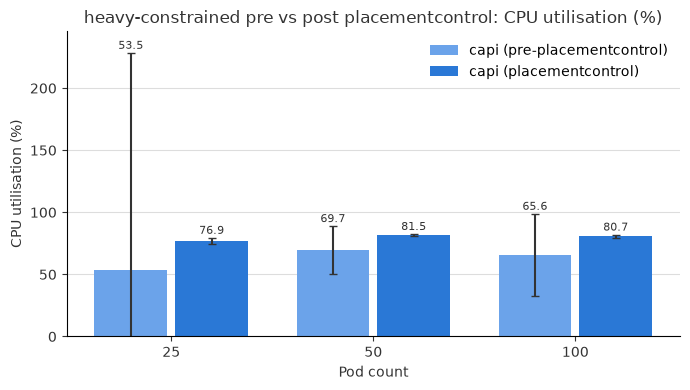

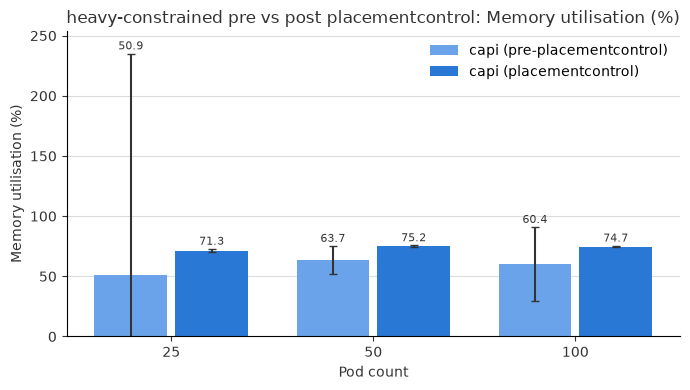

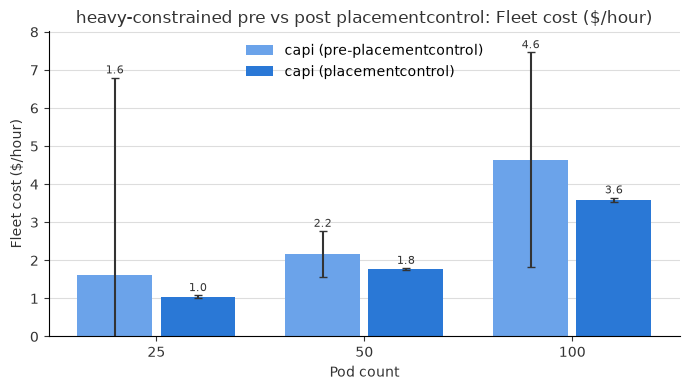

,profile,pod_count,autoscaler,ok_runs,total_runs
0,heavy-constrained,25,capi (placementcontrol),10,10
1,heavy-constrained,25,capi (pre-placementcontrol),2,2
2,heavy-constrained,50,capi (placementcontrol),10,10
3,heavy-constrained,50,capi (pre-placementcontrol),2,2
4,heavy-constrained,100,capi (placementcontrol),10,10
5,heavy-constrained,100,capi (pre-placementcontrol),2,2
6,light-constrained,25,capi (placementcontrol),10,10
7,light-constrained,25,capi (pre-placementcontrol),2,2
8,light-constrained,50,capi (placementcontrol),10,10
9,light-constrained,50,capi (pre-placementcontrol),2,2


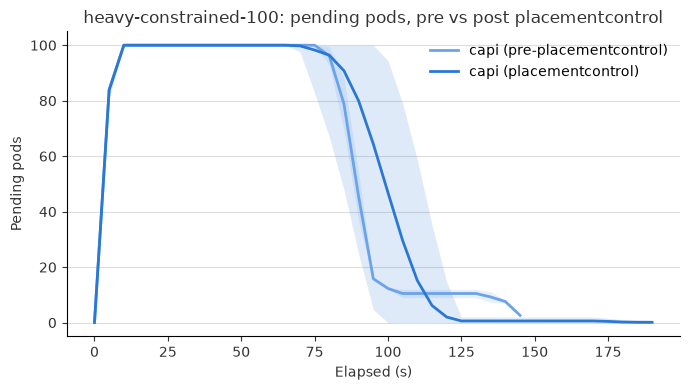

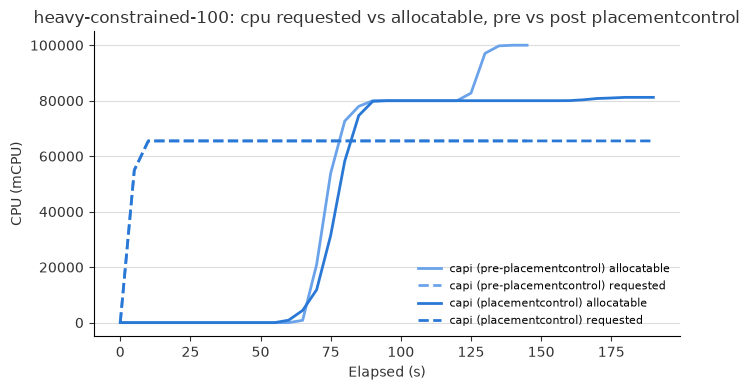

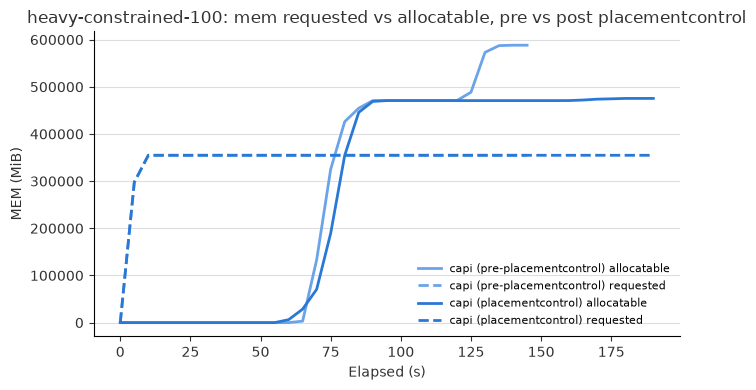

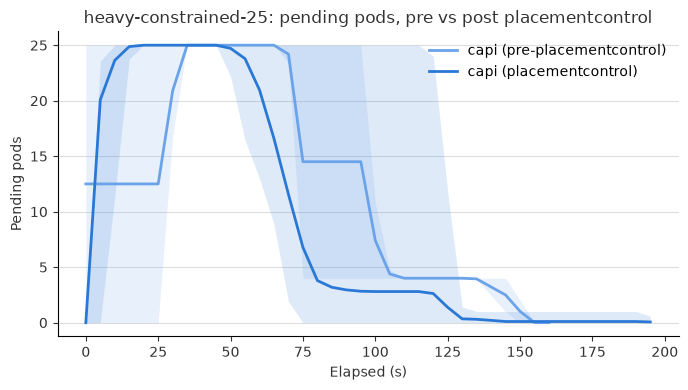

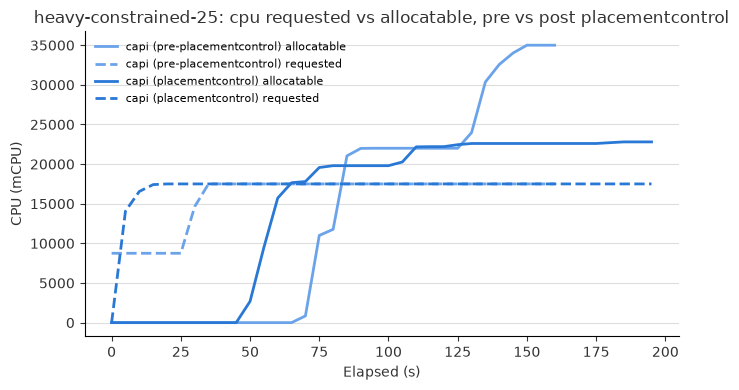

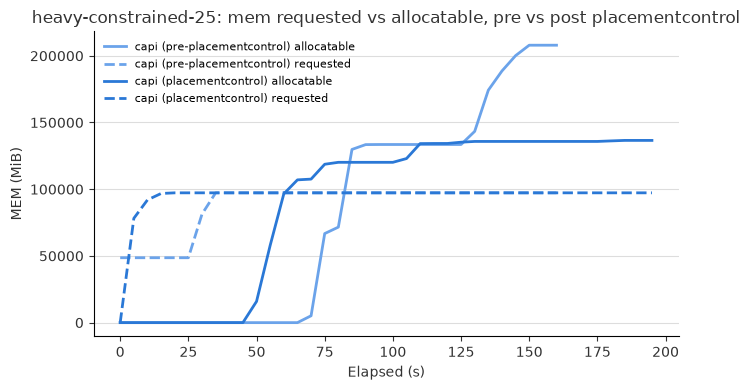

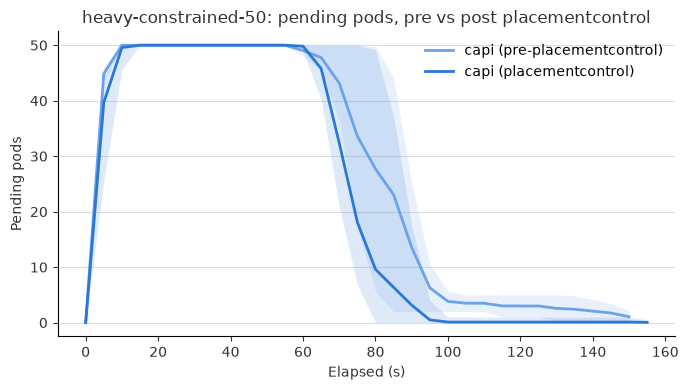

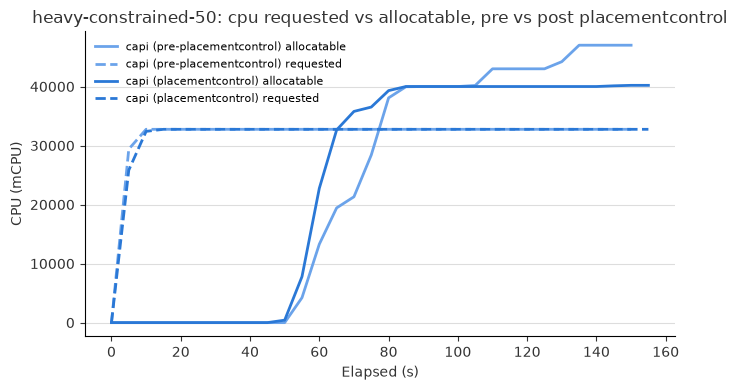

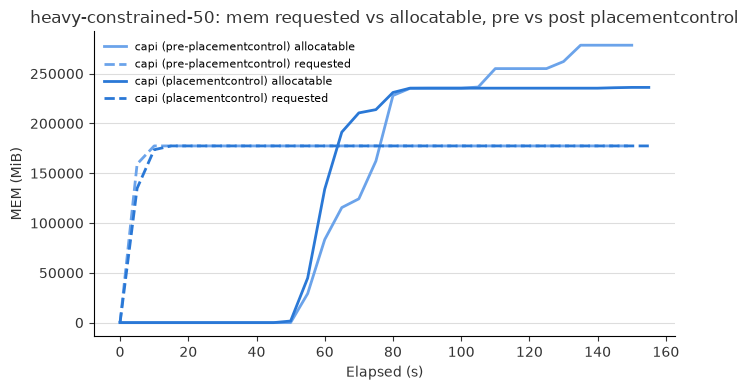

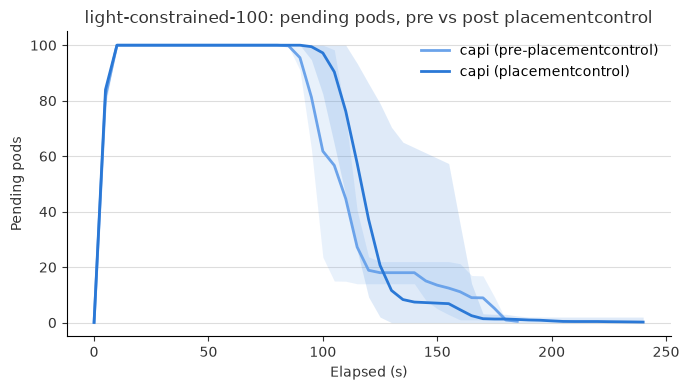

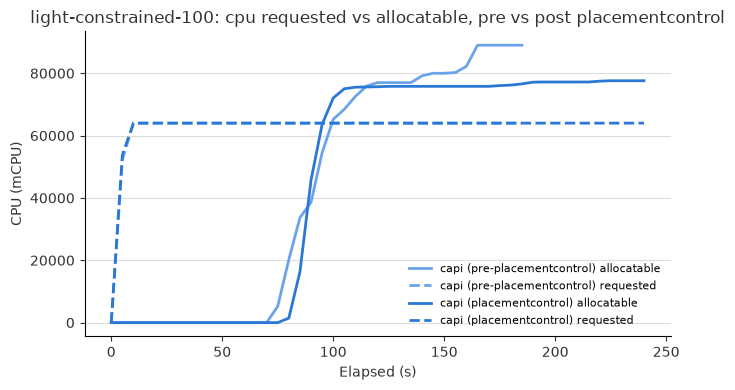

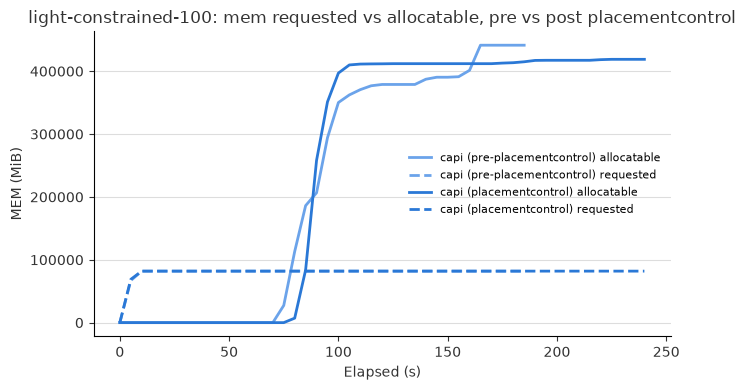

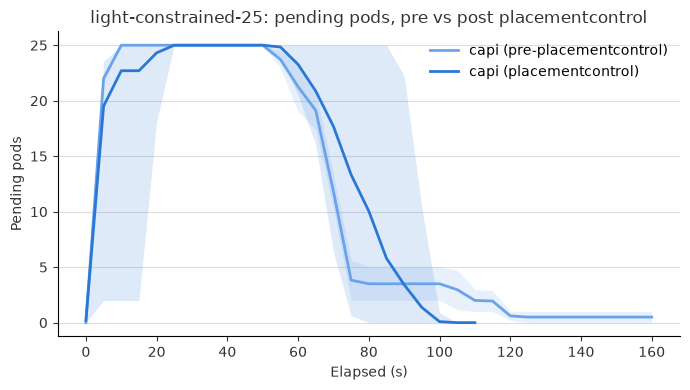

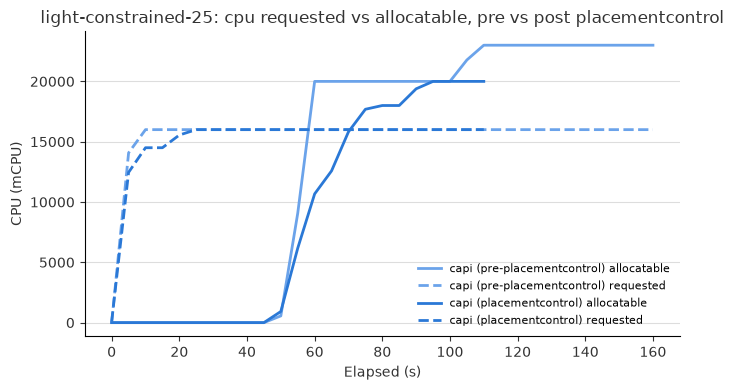

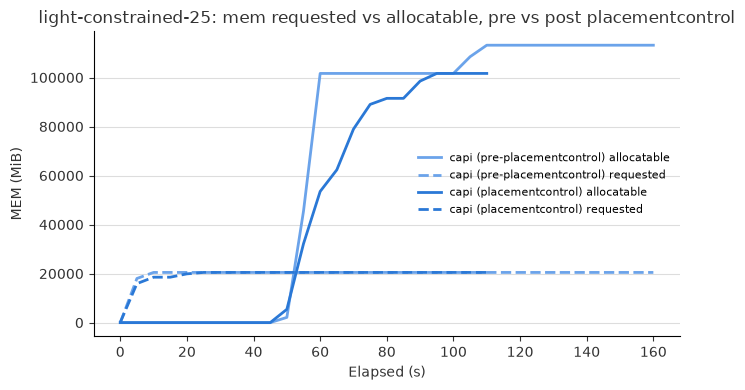

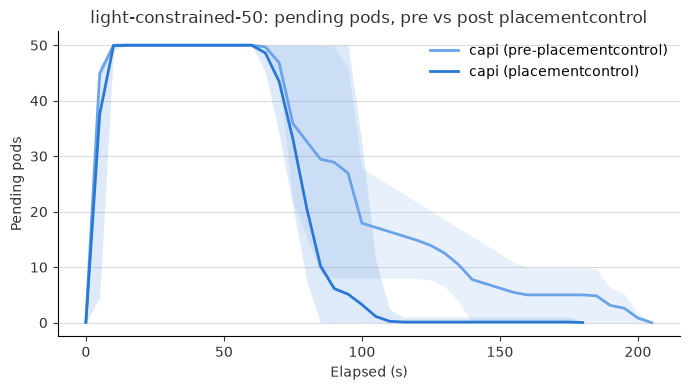

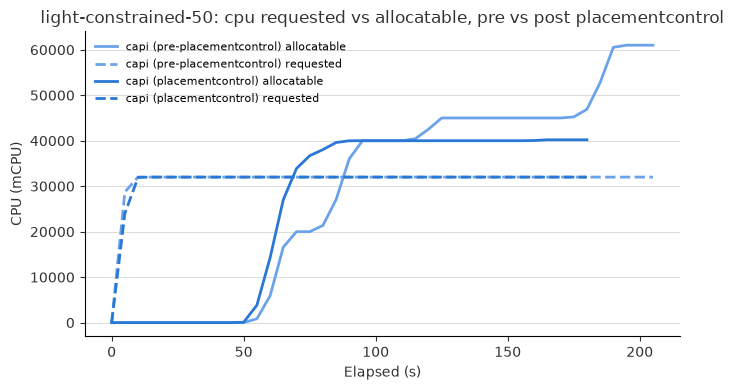

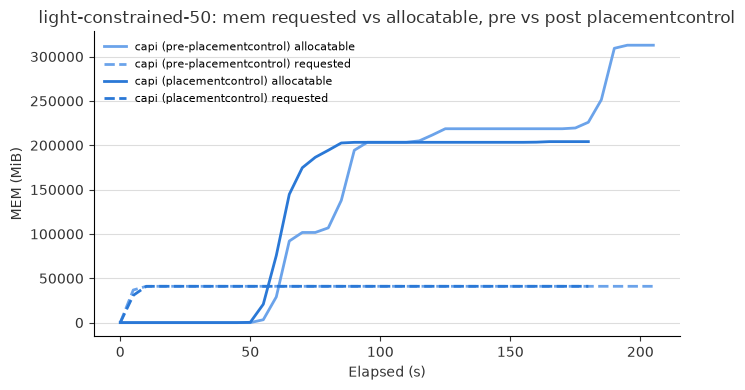

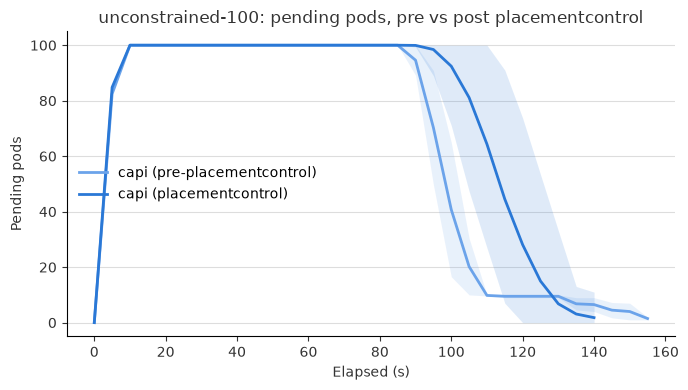

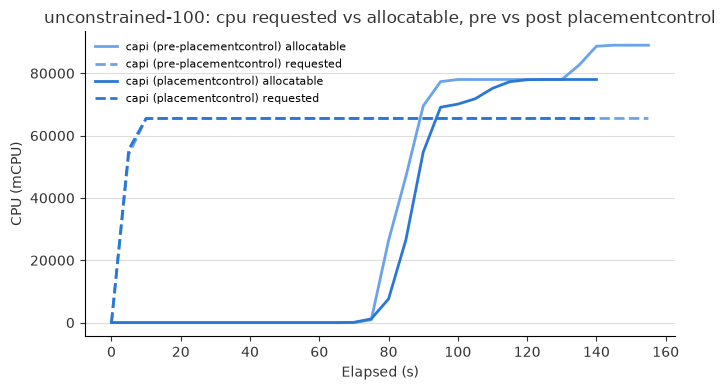

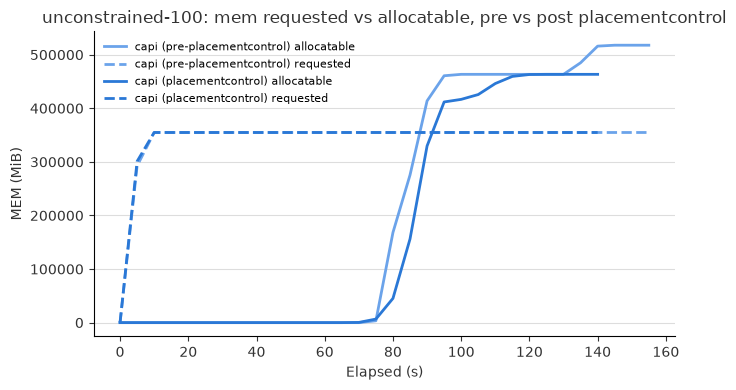

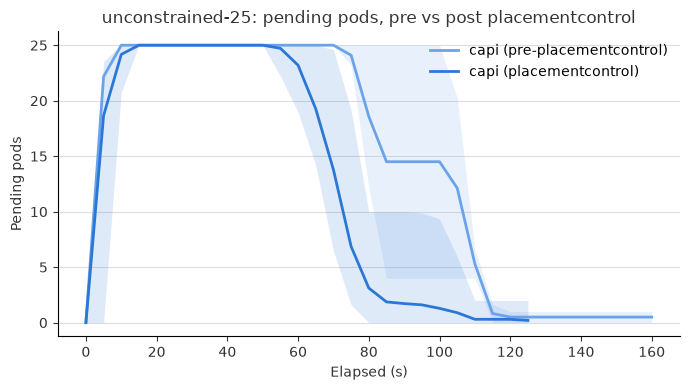

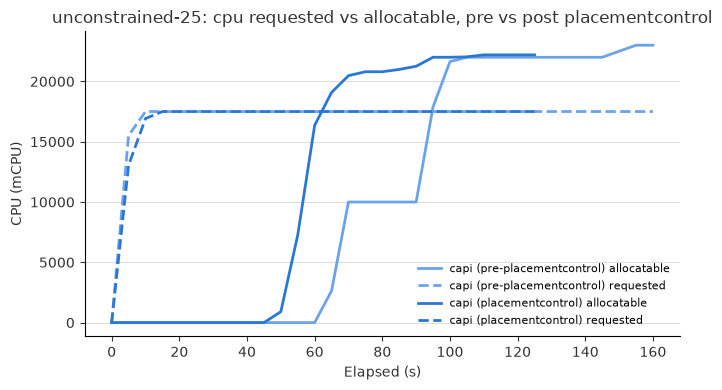

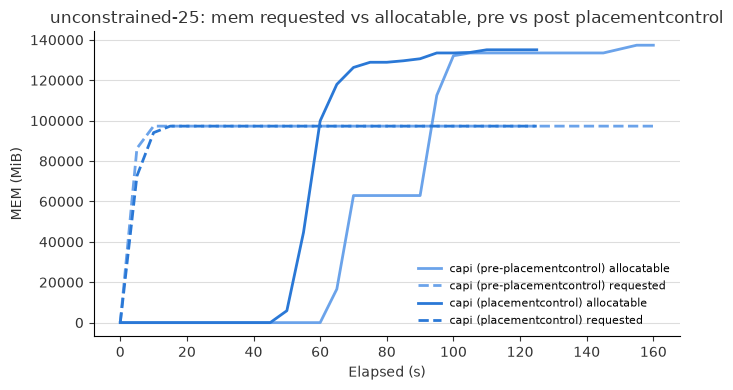

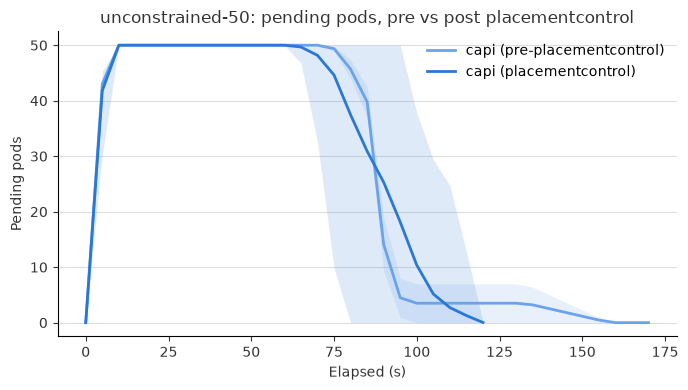

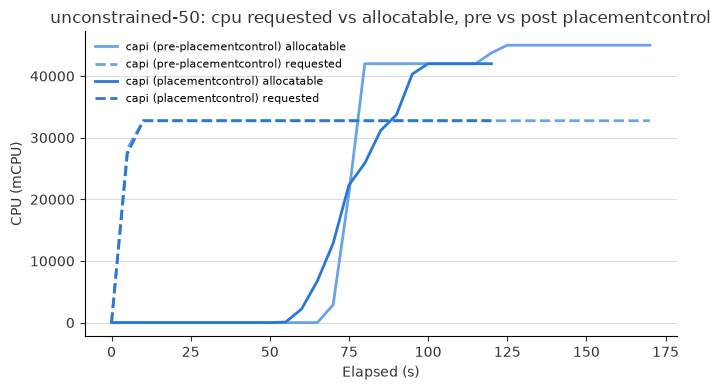

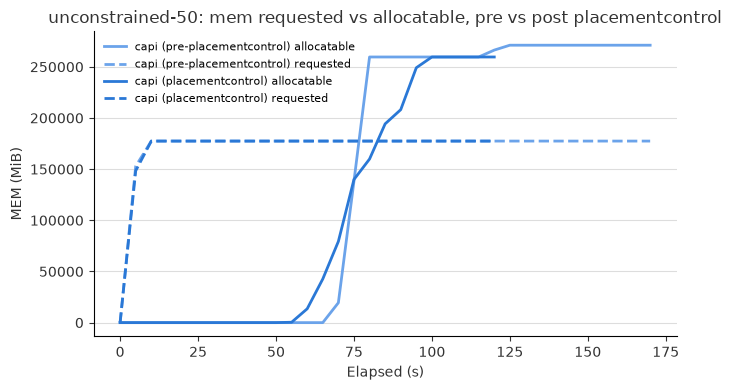

In [13]:
pp = prepost.copy()
pp["autoscaler"] = pp["cohort"].map({"pre-placementcontrol": "capi (pre-placementcontrol)",
                                     "placementcontrol": "capi (placementcontrol)"})
if pp["cohort"].nunique() < 2:
    print(summaries.no_data_note("pre vs post placementcontrol",
          "Need capi runs from both cohorts loaded."))
else:
    for profile in config.PROFILES:
        prof_df = pp[pp["profile"] == profile]
        if prof_df.empty:
            continue
        table = stats.score_table(prof_df, ["autoscaler", "pod_count"], RQ1_METRICS)
        export.save_table(table, f"rq4_prepost_scores_{profile}")
        display(table)
        note = timeout_note(table)
        for metric in CHART_METRICS:
            if table[f"{metric}_mean"].notna().any():
                fig = plotting.comparison_bars(table, metric,
                        f"{profile} pre vs post placementcontrol: {plotting.METRIC_LABELS[metric]}")
                if note:
                    plotting.add_footnote(fig, note)
                export.save_figure(fig, f"rq4_prepost_{profile}_{metric}")
                plt.show()
    pp_feas = (pp.groupby(["profile", "pod_count", "autoscaler"])
        .agg(ok_runs=("timed_out", lambda s: int((~s).sum())),
             total_runs=("timed_out", "count")).reset_index())
    export.save_table(pp_feas, "rq4_prepost_feasibility")
    display(pp_feas)
    pp_ts = timeseries[timeseries["run_id"].isin(set(pp["run_id"]))].copy()
    pp_ts["autoscaler"] = pp_ts["run_id"].map(pp.set_index("run_id")["autoscaler"])
    for scenario in sorted(pp_ts["scenario"].unique()):
        fig = plotting.timeseries_overlay(pp_ts, "pending_pods", scenario,
                f"{scenario}: pending pods, pre vs post placementcontrol")
        export.save_figure(fig, f"rq4_prepost_{scenario}_pending_pods")
        plt.show()
        for resource in ("cpu", "mem"):
            fig = plotting.requested_vs_allocatable(pp_ts, scenario, resource,
                    f"{scenario}: {resource} requested vs allocatable, pre vs post placementcontrol")
            export.save_figure(fig, f"rq4_prepost_{scenario}_{resource}_req_vs_alloc")
            plt.show()

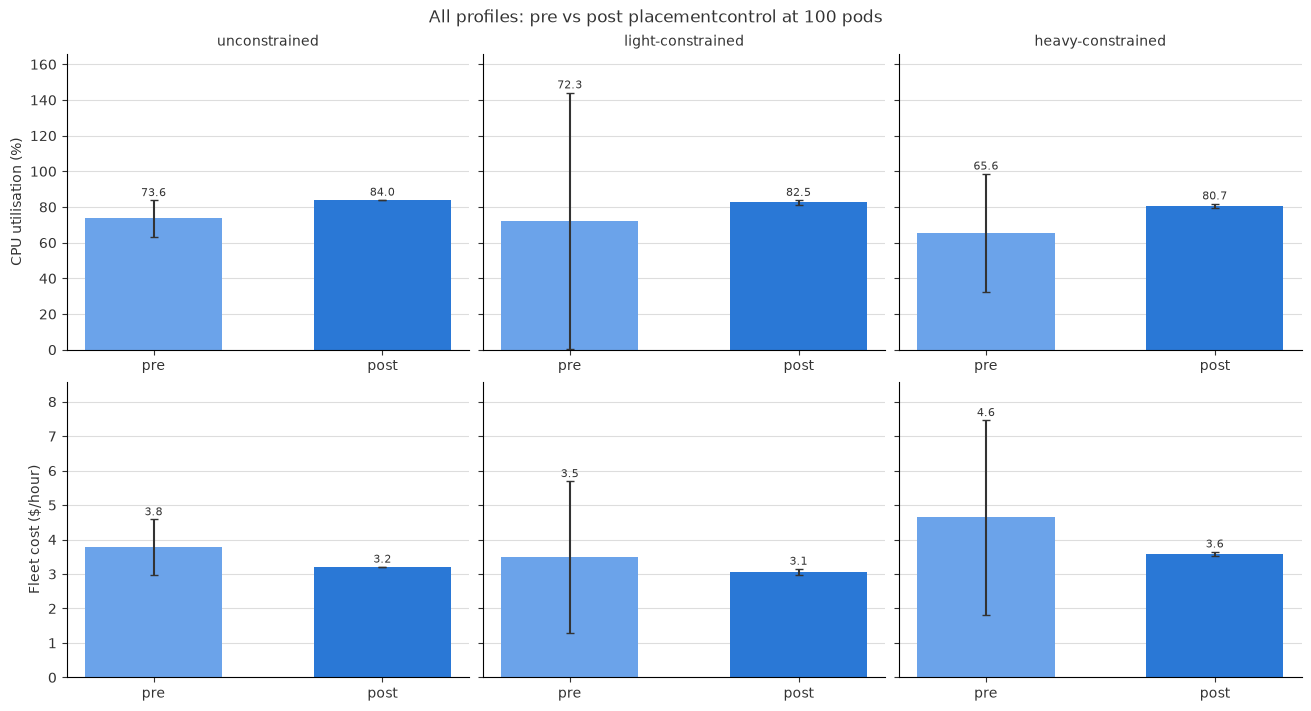

In [14]:
# Composite: the RQ4 answer in one figure. 100-pod runs only (clearest effect),
# CPU utilisation and fleet cost, pre vs post placementcontrol per profile.
# Latency stays out; it is secondary to RQ4. Worker count stays in the table.
if pp["cohort"].nunique() < 2:
    print(summaries.no_data_note("RQ4 prepost composite",
          "Need capi runs from both cohorts loaded."))
else:
    PREPOST_METRICS = ["workload_cpu_util_pct", "cost_per_hour"]
    tables = {}
    for profile in config.PROFILES:
        prof_df = pp[(pp["profile"] == profile) & (pp["pod_count"] == 100)]
        if not prof_df.empty:
            tables[profile] = stats.score_table(prof_df, ["autoscaler", "pod_count"],
                                                PREPOST_METRICS)
    fig = plotting.prepost_composite(tables, PREPOST_METRICS, 100,
            "All profiles: pre vs post placementcontrol at 100 pods")
    export.save_figure(fig, "rq4_prepost_composite_100pods")
    plt.show()

## Cost and instance mix

What each autoscaler actually provisioned, and what it costs. Timed-out runs
are included (the fleet as it stood at timeout) and flagged per chart.

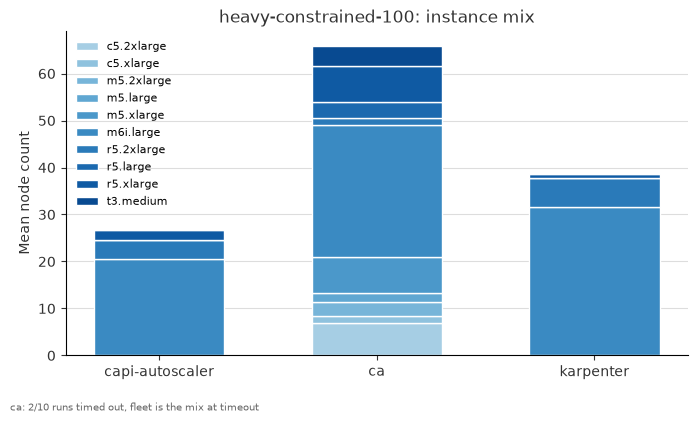

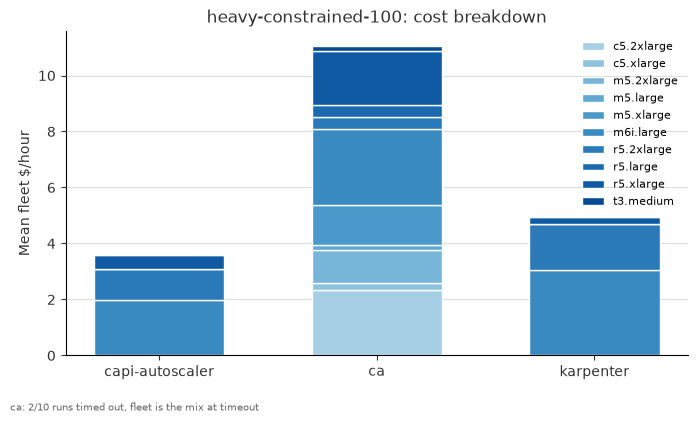

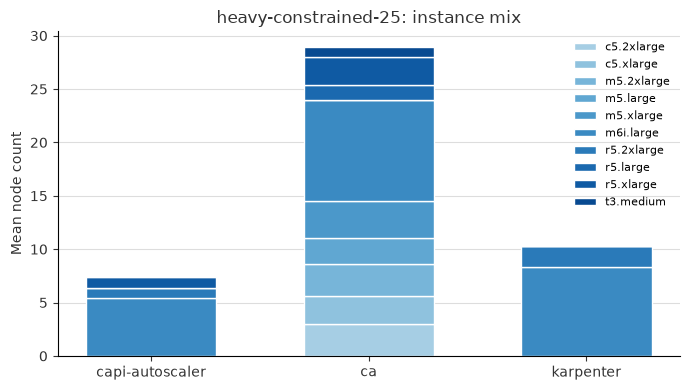

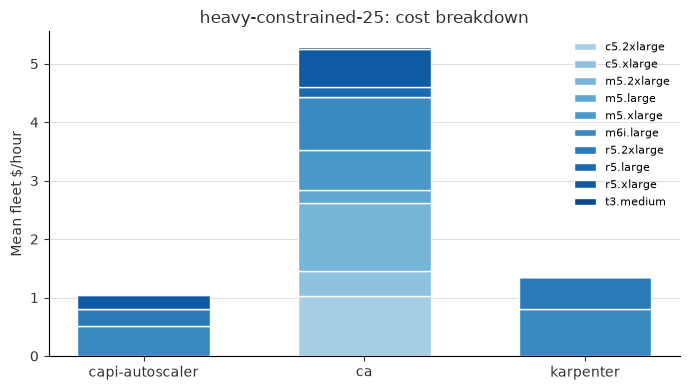

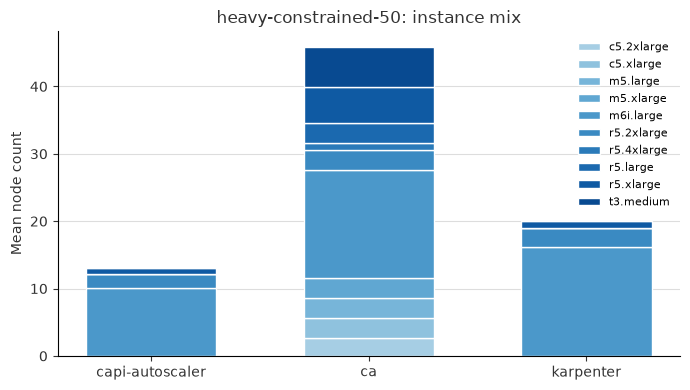

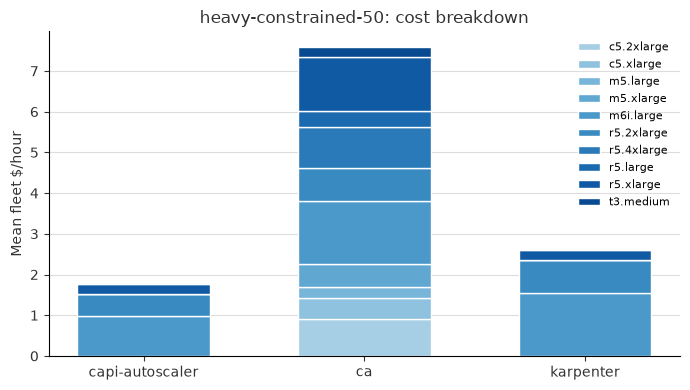

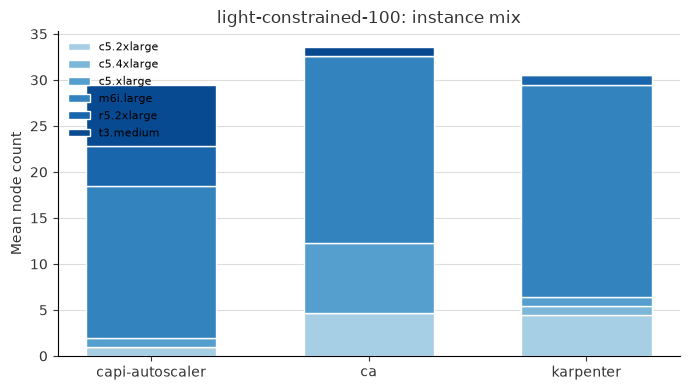

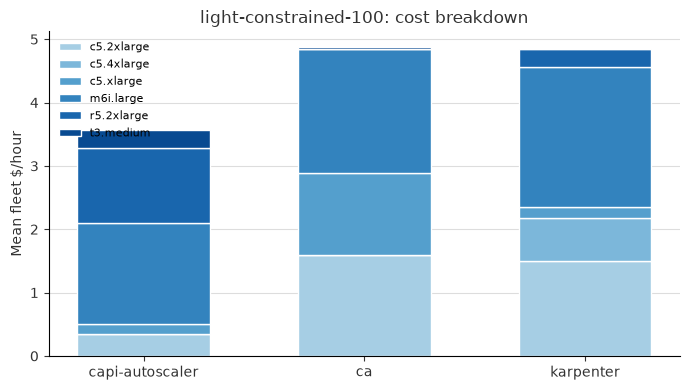

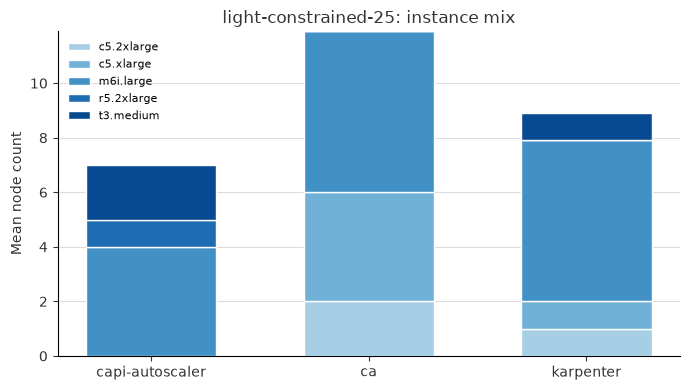

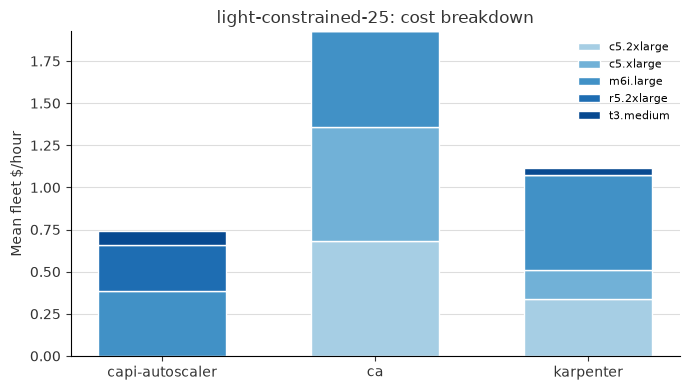

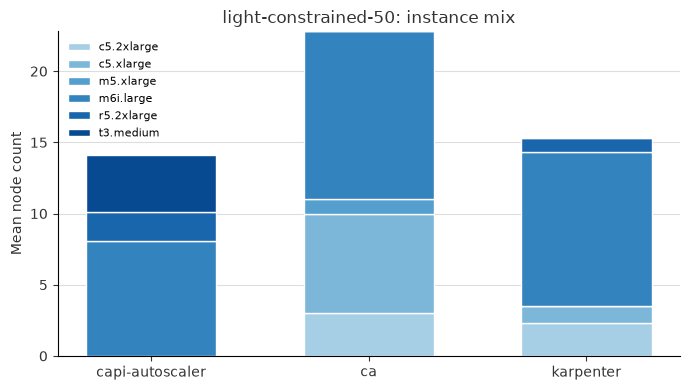

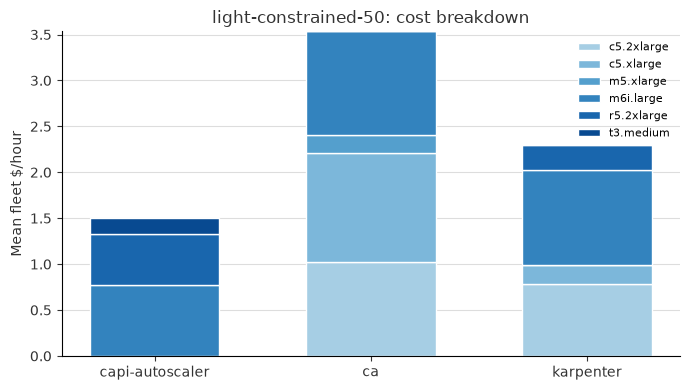

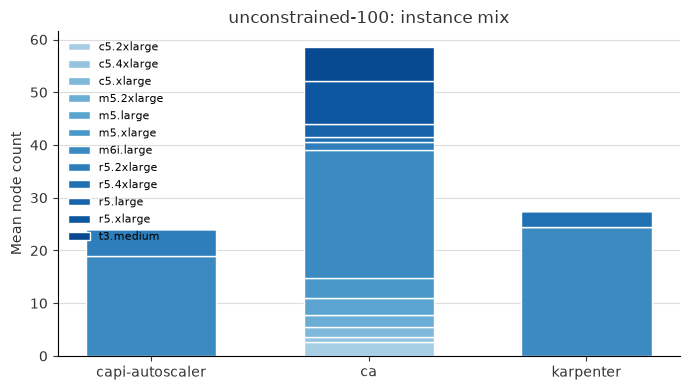

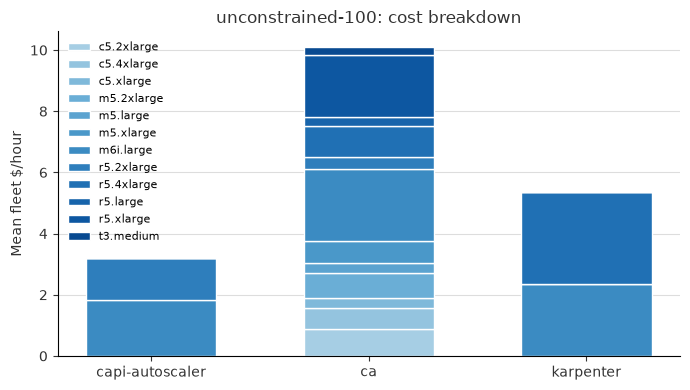

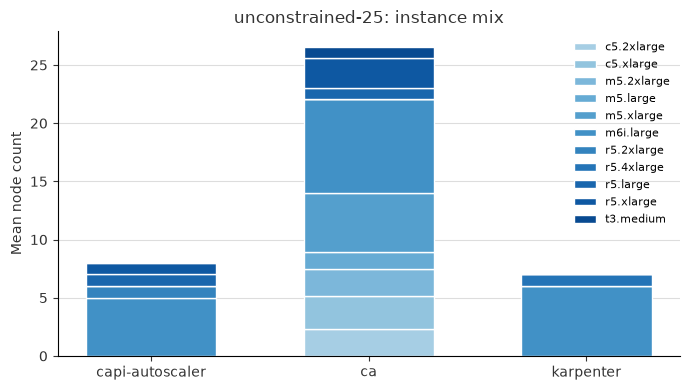

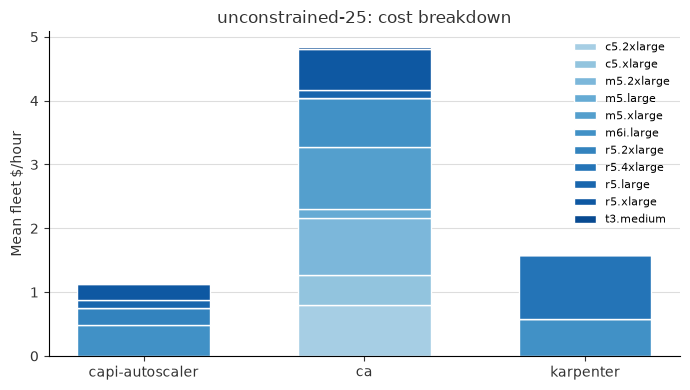

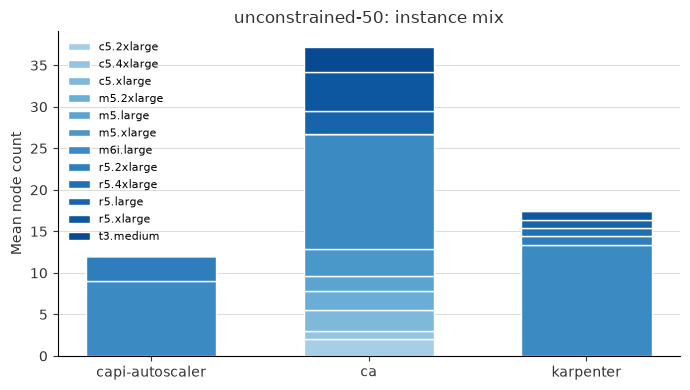

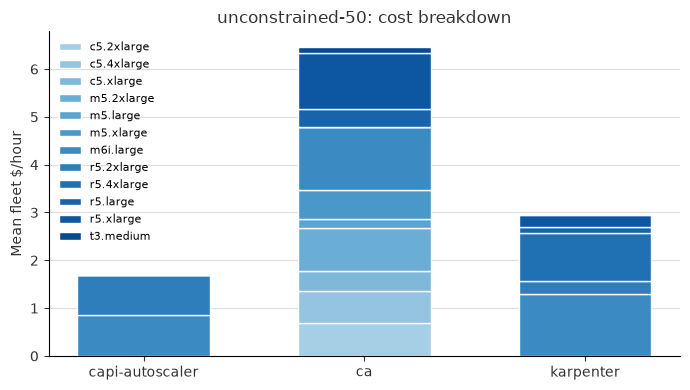

In [15]:
if instances.empty:
    print(summaries.no_data_note("instance mix", "No instance_counts data loaded."))
else:
    mix_table = (instances.groupby(["scenario", "autoscaler", "instance_type"])
                 [["count", "hourly_cost"]].mean().round(3).reset_index())
    export.save_table(mix_table, "cost_instance_mix")
    for scenario in sorted(instances["scenario"].unique()):
        t = (main[main["scenario"] == scenario].groupby("autoscaler")["timed_out"]
             .agg(["sum", "count"]))
        note = "; ".join(
            f"{plotting.display_name(a)}: {int(r['sum'])}/{int(r['count'])} runs timed out, fleet is the mix at timeout"
            for a, r in t.iterrows() if r["sum"] > 0)
        fig = plotting.instance_mix_stacked(instances, scenario, f"{scenario}: instance mix")
        if note:
            plotting.add_footnote(fig, note)
        export.save_figure(fig, f"cost_{scenario}_instance_mix")
        plt.show()
        fig = plotting.instance_mix_stacked(instances, scenario,
                                            f"{scenario}: cost breakdown", by_cost=True)
        if note:
            plotting.add_footnote(fig, note)
        export.save_figure(fig, f"cost_{scenario}_breakdown")
        plt.show()

## Karpenter with consolidation

Optional scenario (`make bench-karpenter-consolidation`): the NodePool is
patched to `WhenEmptyOrUnderutilized` with `consolidateAfter: 1m` and each run
holds the full 15-minute window after provisioning, so Karpenter can
consolidate the fleet it scaled up. Node count, utilisation and cost are read
from the last sample of the window; latency is still time-to-all-running. The
other systems' numbers are the same runs as sections 2-6. The settle table
shows when each fleet stopped changing size (`settled_s`, the last
worker-node-count change in the run) against provisioning latency and the
peak node count. The overlays show the provisioning peak and the
consolidation convergence against plain karpenter, which stops at its steady
state.

,autoscaler,pod_count,n_ok,n_total,n_timed_out,latency_s_mean,latency_s_ci95,worker_nodes_mean,worker_nodes_ci95,workload_cpu_util_pct_mean,workload_cpu_util_pct_ci95,workload_mem_util_pct_mean,workload_mem_util_pct_ci95,cost_per_hour_mean,cost_per_hour_ci95
0,capi-autoscaler,25,10,10,0,94.286758,10.530370,7.1,0.226216,78.84,1.493024,72.13,1.741861e+00,1.02160,2.850318e-02
1,capi-autoscaler,50,10,10,0,103.421452,8.884194,12.0,0.000000,78.00,0.000000,68.30,1.071573e-14,1.69500,1.674333e-16
2,capi-autoscaler,100,10,10,0,128.375230,5.148752,24.0,0.000000,84.00,0.000000,76.60,0.000000e+00,3.20900,3.348665e-16
3,cas,25,10,10,0,395.235017,115.703864,16.6,3.038747,34.91,9.311094,46.36,8.861203e+00,2.70676,5.426048e-01
4,cas,50,10,10,0,457.179166,153.436691,26.7,3.439835,44.79,9.444484,49.25,5.600965e+00,3.99024,6.285969e-01
5,cas,100,10,10,0,395.597824,87.277516,47.4,5.977500,46.48,5.605587,52.30,3.612690e+00,7.02516,8.758293e-01
6,karpenter,25,10,10,0,54.167535,13.736845,7.0,0.584086,63.88,2.630724,58.26,1.460683e+00,1.58400,5.607230e-02
7,karpenter,50,10,10,0,67.015810,10.531829,15.5,0.907999,66.39,2.491901,63.31,1.784876e+00,2.58150,8.733167e-02
8,karpenter,100,10,10,0,66.739908,7.575712,27.5,1.359387,69.07,1.973270,64.83,1.165761e+00,5.37600,1.305012e-01
9,karpenter-consolidation,25,2,2,0,45.419346,18.022117,6.0,0.000000,68.50,0.000000,60.80,0.000000e+00,1.48800,0.000000e+00


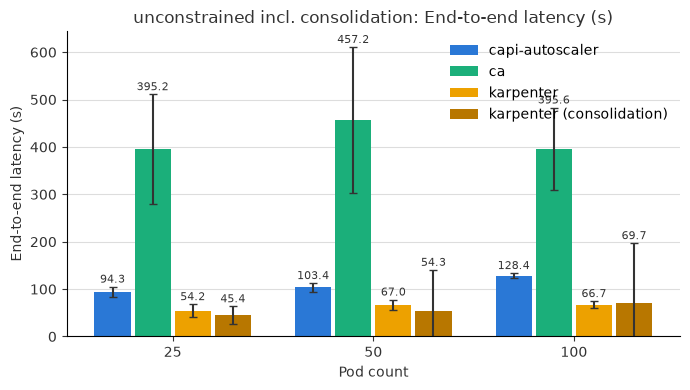

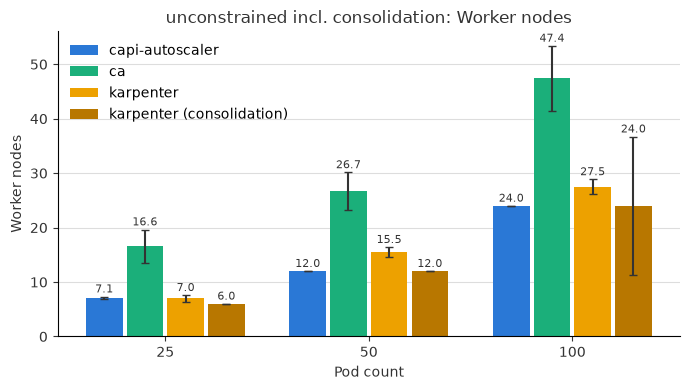

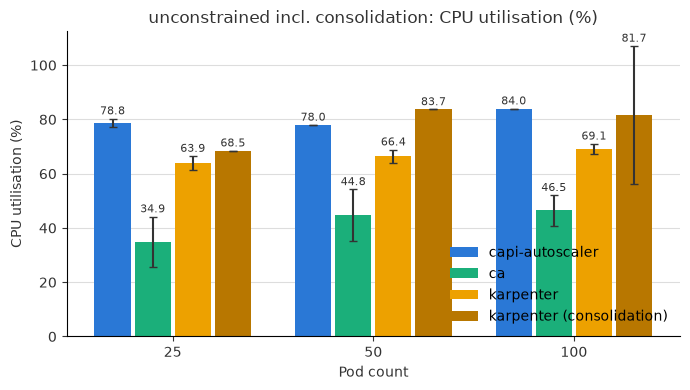

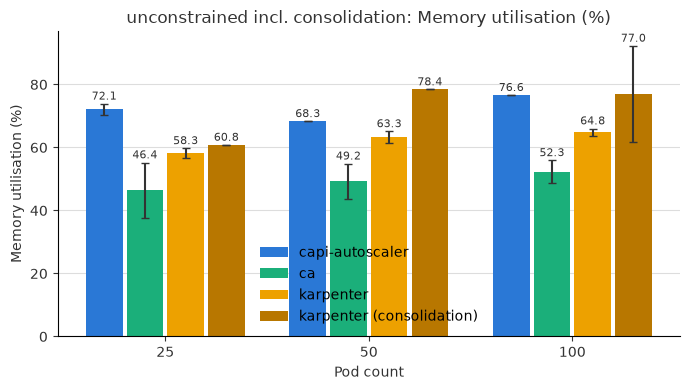

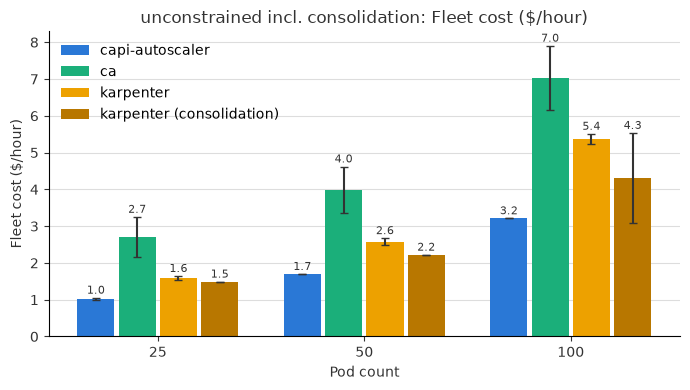

,autoscaler,pod_count,n_ok,n_total,n_timed_out,latency_s_mean,latency_s_ci95,worker_nodes_mean,worker_nodes_ci95,workload_cpu_util_pct_mean,workload_cpu_util_pct_ci95,workload_mem_util_pct_mean,workload_mem_util_pct_ci95,cost_per_hour_mean,cost_per_hour_ci95
0,capi-autoscaler,25,10,10,0,89.195210,7.206443,7.0,0.000000,80.00,0.000000,20.10,0.000000,0.74420,0.000000
1,capi-autoscaler,50,10,10,0,99.237432,20.764117,14.1,0.226216,79.62,0.859620,20.03,0.158351,1.49800,0.021717
2,capi-autoscaler,100,10,10,0,175.998559,29.582880,24.9,2.118069,82.53,1.361498,19.74,1.457176,3.06538,0.082638
3,cas,25,10,10,0,111.612922,17.134043,8.9,0.711372,57.54,0.995349,26.97,0.713008,1.24640,0.021717
4,cas,50,10,10,0,108.655575,19.731611,15.7,0.757813,65.64,1.314389,29.34,0.742043,2.20600,0.045404
5,cas,100,10,10,0,156.673425,22.957416,29.0,1.877575,68.45,2.909753,31.84,1.408767,4.20112,0.183257
6,karpenter,25,10,10,0,63.406454,9.002618,7.8,0.564281,73.08,4.385682,33.80,2.495218,1.00804,0.075796
7,karpenter,50,10,10,0,75.395519,11.902801,13.8,0.941811,76.10,3.070577,34.74,3.339899,1.94850,0.075429
8,karpenter,100,10,10,0,82.654171,4.322520,28.1,1.734320,75.51,2.708392,33.41,2.430682,3.93900,0.143052
9,karpenter-consolidation,25,2,2,0,70.118666,50.436146,7.0,0.000000,82.10,0.000000,38.30,0.000000,0.86160,0.000000


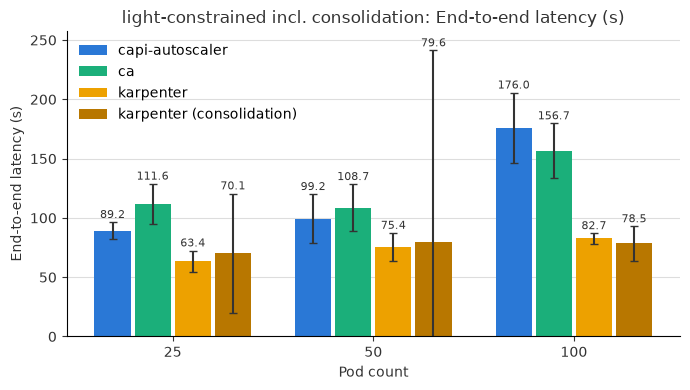

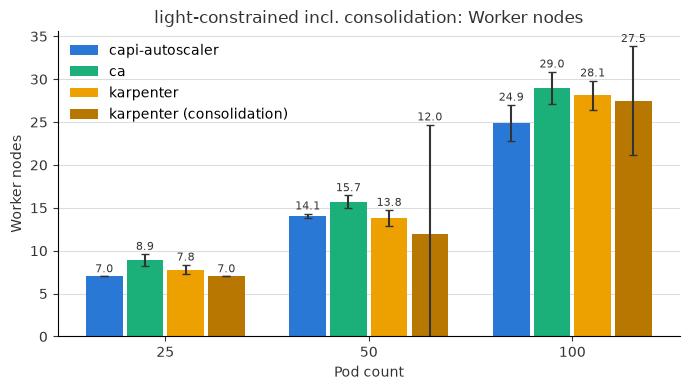

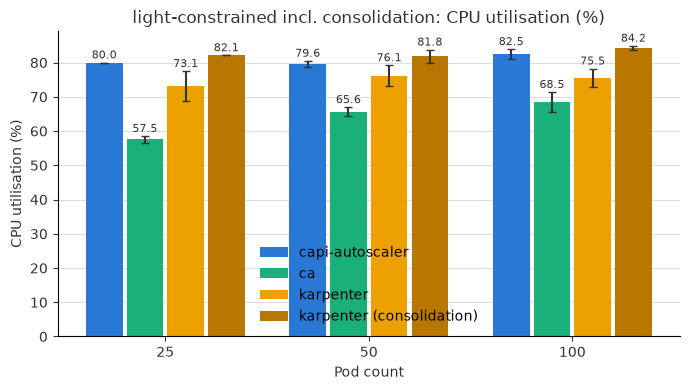

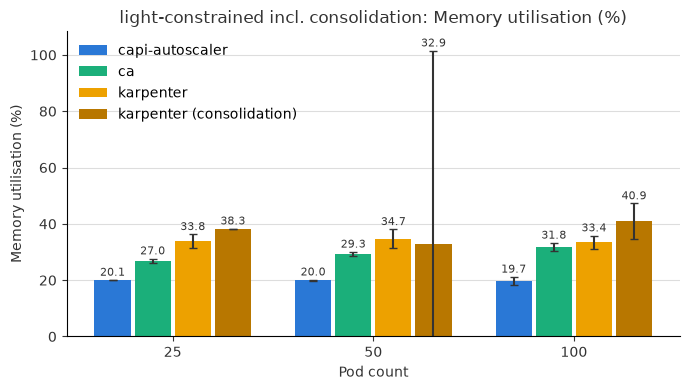

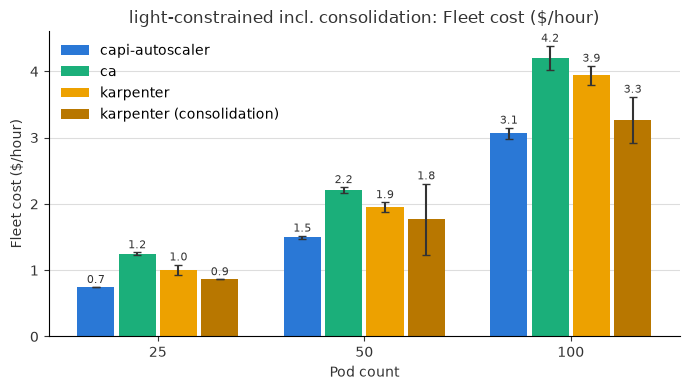

,autoscaler,pod_count,n_ok,n_total,n_timed_out,latency_s_mean,latency_s_ci95,worker_nodes_mean,worker_nodes_ci95,workload_cpu_util_pct_mean,workload_cpu_util_pct_ci95,workload_mem_util_pct_mean,workload_mem_util_pct_ci95,cost_per_hour_mean,cost_per_hour_ci95
0,capi-autoscaler,25,10,10,0,107.873206,30.583568,7.400,0.369409,76.860,2.438098,71.30,1.477635,1.047400,0.035463
1,capi-autoscaler,50,10,10,0,91.895645,17.595302,13.100,0.226216,81.510,0.882241,75.16,0.542918,1.775600,0.021717
2,capi-autoscaler,100,10,10,0,140.168642,27.402326,26.600,0.603242,80.720,1.180182,74.68,0.723890,3.589600,0.057911
3,cas,25,10,10,0,384.435824,116.545556,18.100,2.769539,33.980,7.232601,42.31,5.308491,2.742720,0.469988
4,cas,50,10,10,0,266.498956,112.565649,26.600,5.105330,45.760,8.378347,48.73,5.401147,3.685580,0.779994
5,cas,100,8,10,2,446.967208,63.585297,60.375,5.910505,32.675,5.934276,42.10,3.588357,9.927025,1.382701
6,karpenter,25,10,10,0,61.172711,10.068498,10.300,1.014474,55.330,3.358548,52.94,2.046860,1.350800,0.097389
7,karpenter,50,10,10,0,74.223150,10.035121,19.200,1.000364,60.050,3.233689,59.17,4.144552,2.399300,0.124279
8,karpenter,100,10,10,0,80.462738,9.034098,38.200,2.231791,59.390,2.397709,57.68,1.813116,4.831200,0.229716
9,karpenter-consolidation,25,2,2,0,75.937752,53.397243,8.000,0.000000,74.800,0.000000,71.60,0.000000,1.105000,0.000000


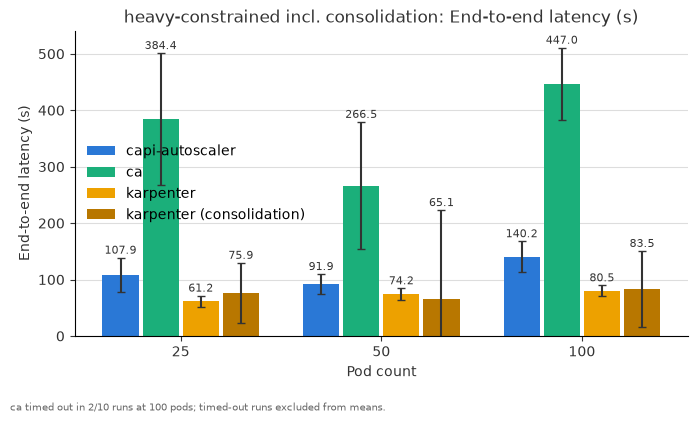

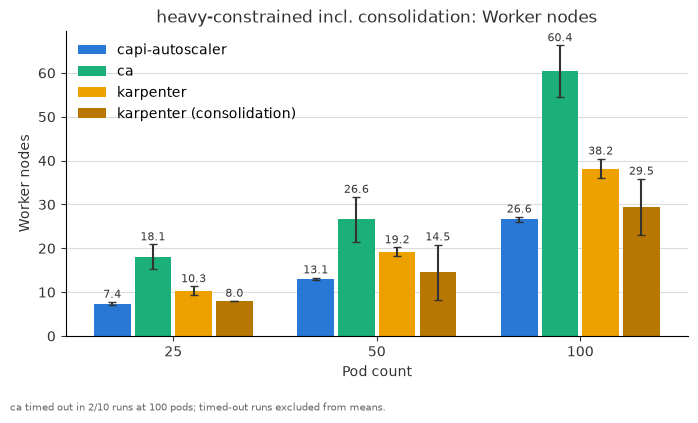

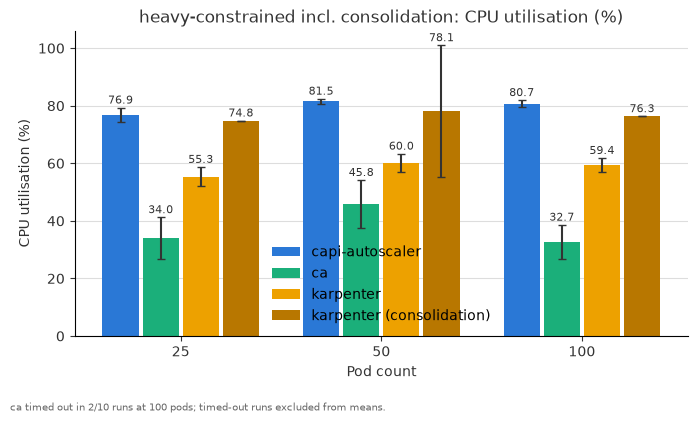

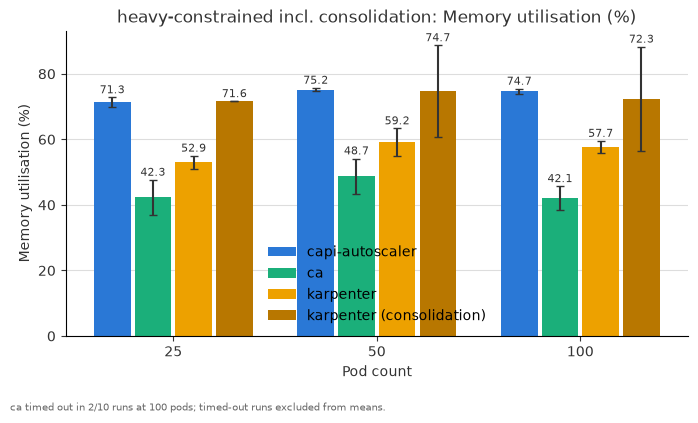

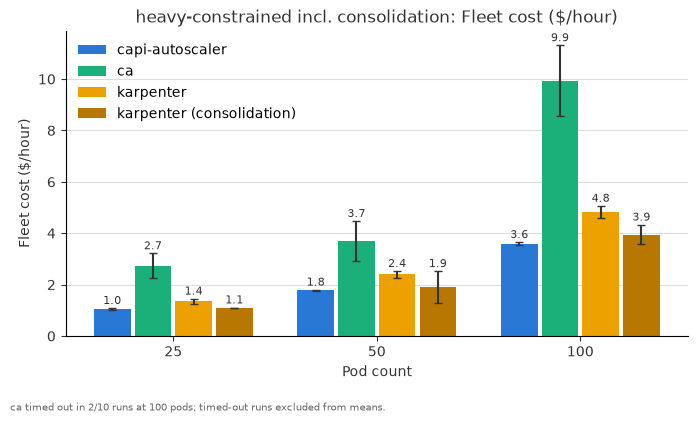

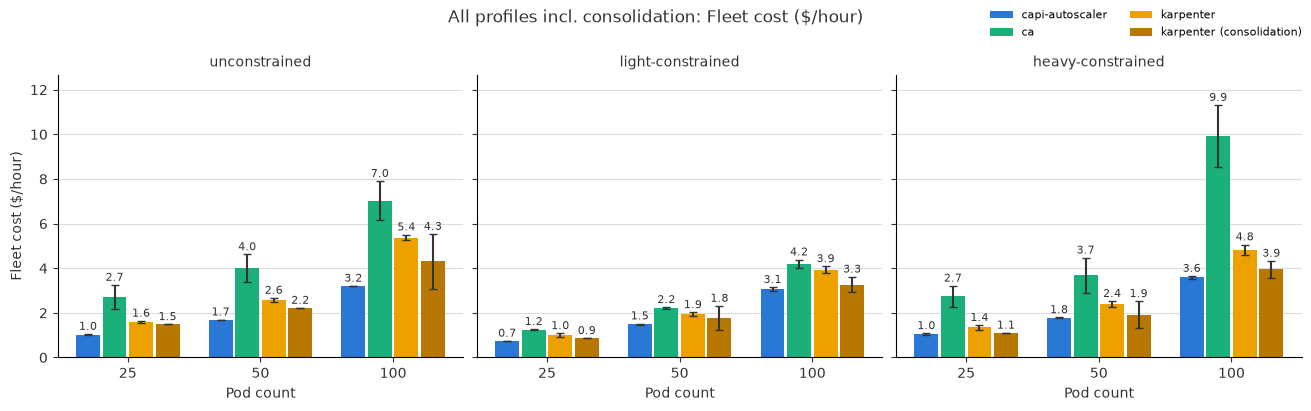

In [16]:
if consol.empty:
    print(summaries.no_data_note("Karpenter consolidation",
          "No karpenter-consolidation runs loaded; run make bench-karpenter-consolidation."))
else:
    four = pd.concat([main, consol], ignore_index=True)
    CONSOL_METRICS = ["latency_s", "worker_nodes", "workload_cpu_util_pct",
                      "workload_mem_util_pct", "cost_per_hour"]
    consol_scores = {}
    for profile in config.PROFILES:
        prof_df = four[four["profile"] == profile]
        if prof_df[prof_df["autoscaler"] == "karpenter-consolidation"].empty:
            continue
        table = stats.score_table(prof_df, ["autoscaler", "pod_count"], CONSOL_METRICS)
        consol_scores[profile] = table
        export.save_table(table, f"consolidation_scores_{profile}")
        display(table)
        note = timeout_note(table)
        for metric in CONSOL_METRICS:
            if table[f"{metric}_mean"].notna().any():
                fig = plotting.comparison_bars(table, metric,
                        f"{profile} incl. consolidation: {plotting.METRIC_LABELS[metric]}")
                if note:
                    plotting.add_footnote(fig, note)
                export.save_figure(fig, f"consolidation_{profile}_{metric}")
                plt.show()

    # Composite: fleet cost across all three profiles with all four systems,
    # same shape as the RQ1 composites
    fig = plotting.comparison_bars_composite(
        consol_scores, "cost_per_hour",
        f"All profiles incl. consolidation: {plotting.METRIC_LABELS['cost_per_hour']}")
    export.save_figure(fig, "consolidation_composite_cost_per_hour")
    plt.show()

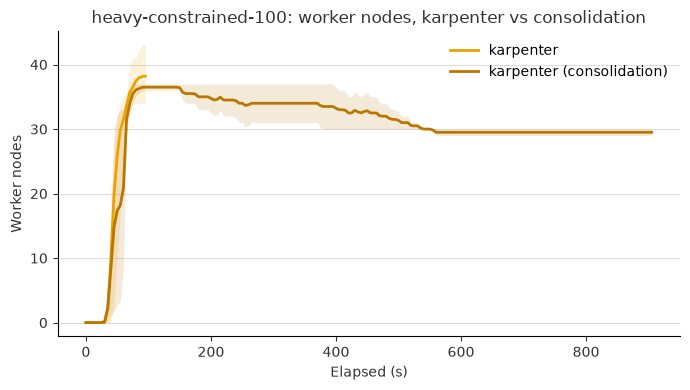

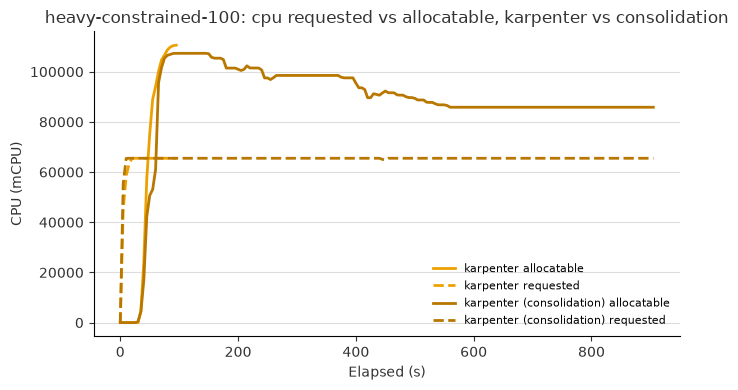

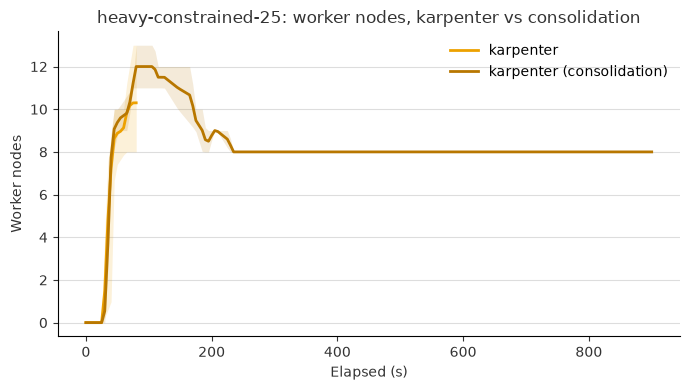

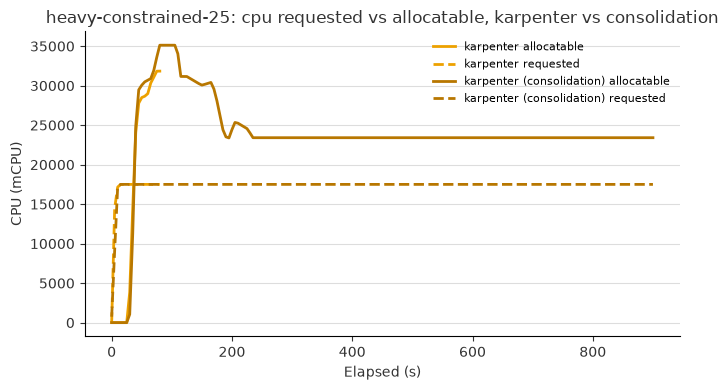

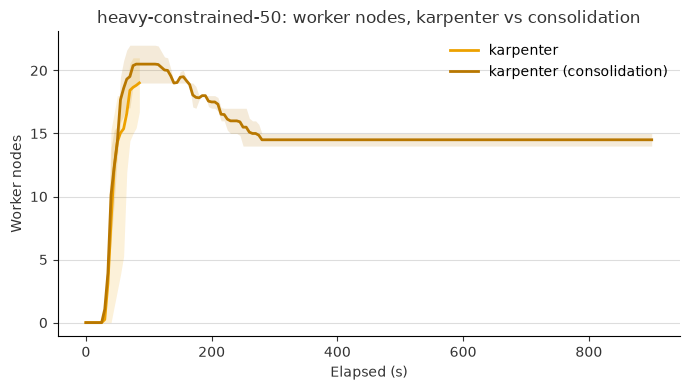

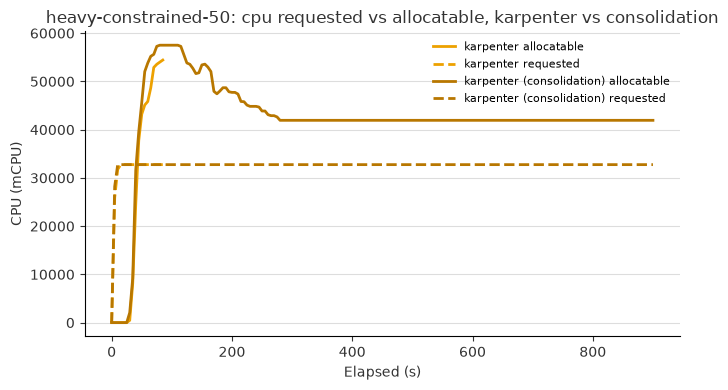

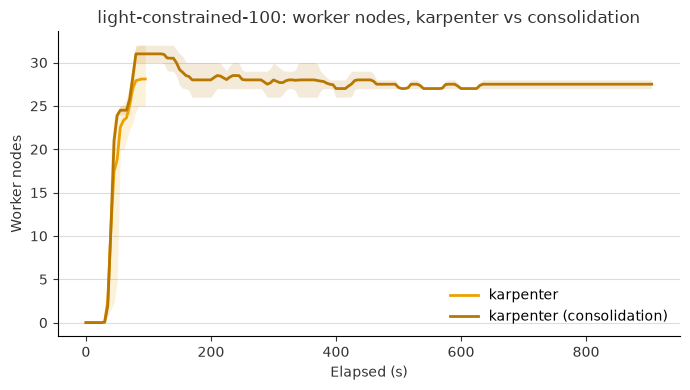

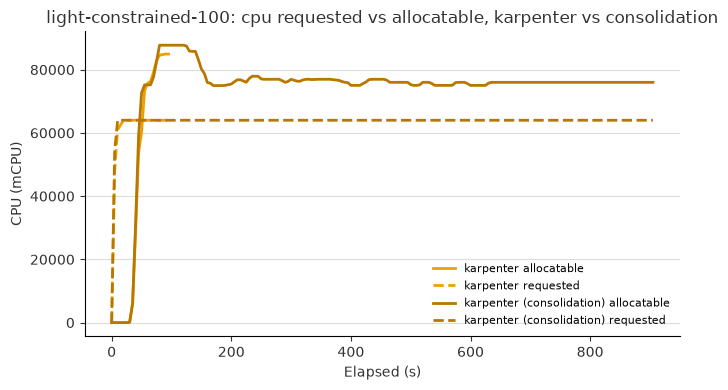

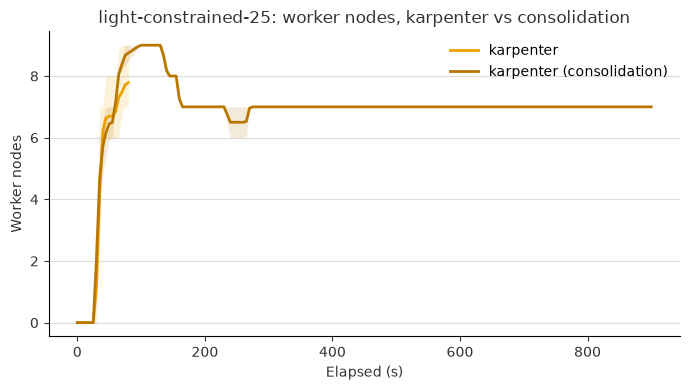

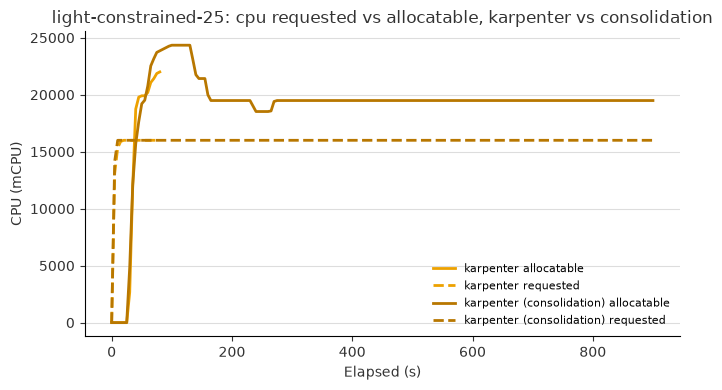

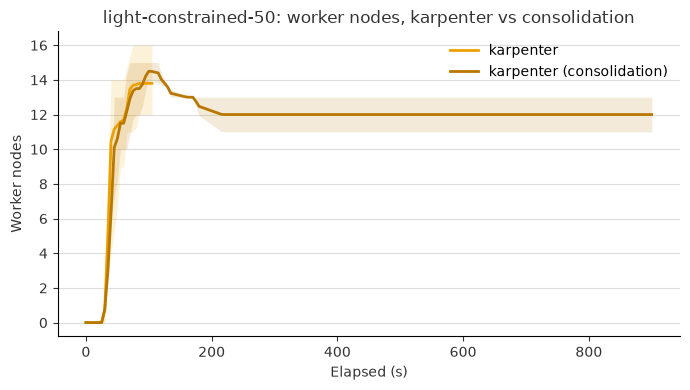

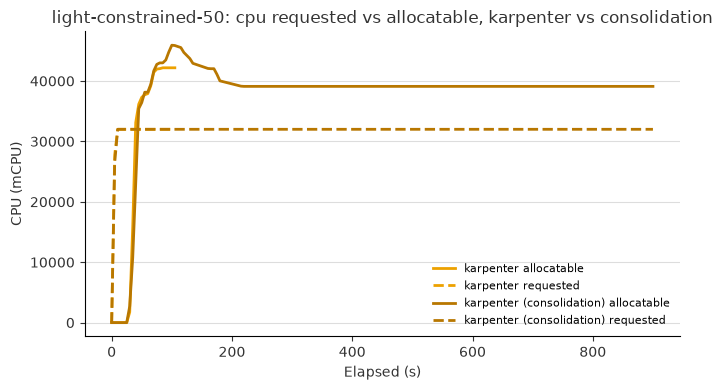

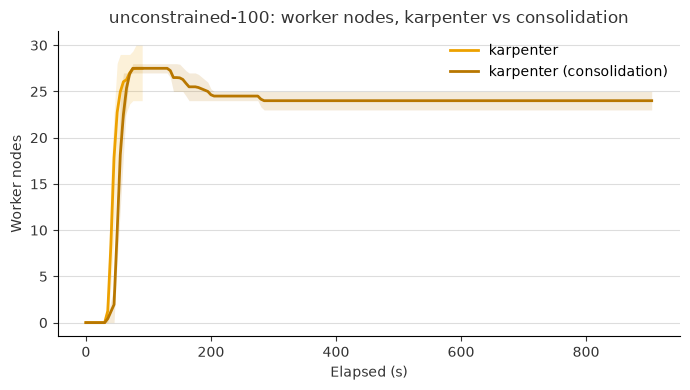

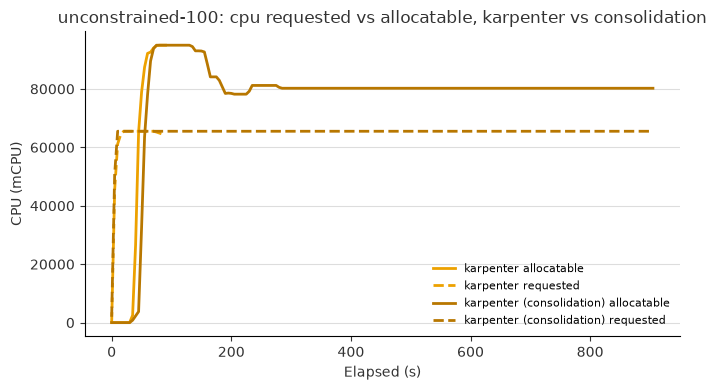

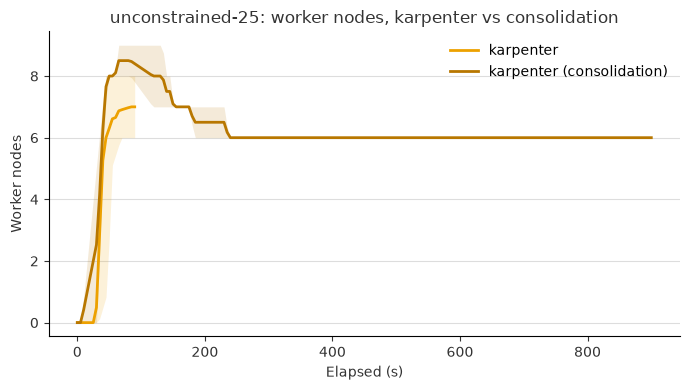

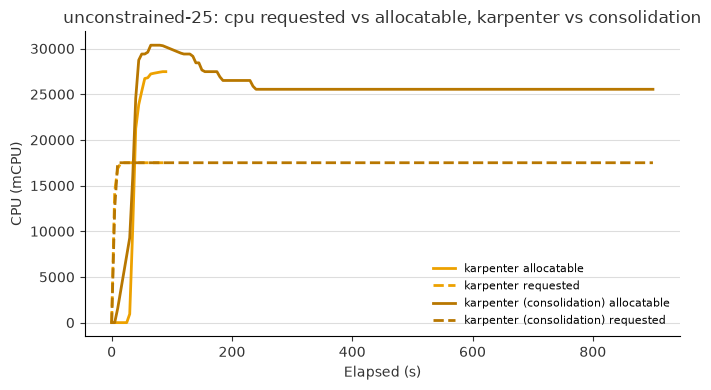

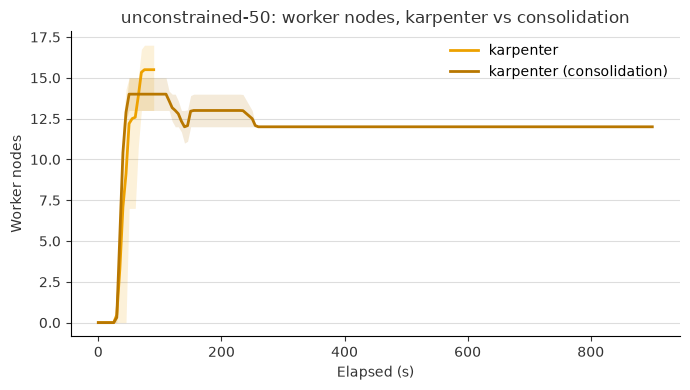

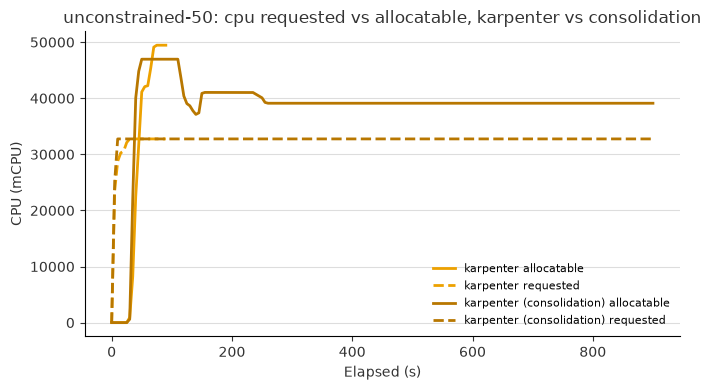

In [17]:
# Convergence overlays: karpenter vs karpenter-consolidation over the full
# window. Worker nodes shows the provision peak then the consolidation
# drawdown; the cpu overlay shows allocatable shrinking towards requested.
if consol.empty:
    print(summaries.no_data_note("Karpenter consolidation overlays",
          "No karpenter-consolidation runs loaded."))
else:
    pair_ids = set(consol["run_id"]) | set(main.loc[main["autoscaler"] == "karpenter", "run_id"])
    pair_ts = timeseries[timeseries["run_id"].isin(pair_ids)]
    for scenario in sorted(consol["scenario"].unique()):
        fig = plotting.timeseries_overlay(pair_ts, "worker_nodes", scenario,
                f"{scenario}: worker nodes, karpenter vs consolidation")
        export.save_figure(fig, f"consolidation_{scenario}_worker_nodes")
        plt.show()
        fig = plotting.requested_vs_allocatable(pair_ts, scenario, "cpu",
                f"{scenario}: cpu requested vs allocatable, karpenter vs consolidation")
        export.save_figure(fig, f"consolidation_{scenario}_cpu_req_vs_alloc")
        plt.show()

### Consolidation churn and remaining headroom

Two findings frame the consolidation result. First, churn: every node
Karpenter consolidates away after the workload is running is a drain that
evicts running pods, so the packing gain has a disruption cost. The drain
counts are measured; the bench pods are stateless, so pod-level impact on
sensitive workloads is inferred, not measured. capi-autoscaler reaches its
fleet at provisioning time with zero post-provisioning drains.

Second, headroom: `make solver-bench-rq4` solves the hardest cluster-shaped
instance (heavy-constrained, 100 pods, 15 MDs) at the production 30s budget
and at 600s, the kind of budget a background scale-down pass could afford
off the provisioning hot path. The 600s cost is an upper bound on what a
solver-driven scale-down consolidator could reach, not a prediction: it
solves greenfield packing on instances that mirror but do not equal the
bench workloads, while a real pass must repack running pods subject to
eviction constraints.

In [18]:
# Churn and settle in one table: nodes drained after all pods were running,
# and when the fleet stopped changing size, per scenario
if consol.empty:
    print(summaries.no_data_note("Consolidation churn", "No karpenter-consolidation runs loaded."))
else:
    consol_ts = timeseries[timeseries["run_id"].isin(set(consol["run_id"]))]
    peaks = consol_ts.groupby("run_id")["worker_nodes"].max().rename("peak_nodes")
    st = loading.settle_times(consol_ts)
    ch = consol.merge(peaks, on="run_id").merge(st, on="run_id")
    ch["drained_nodes"] = ch["peak_nodes"] - ch["worker_nodes"]
    ch["drained_pct_of_peak"] = (ch["drained_nodes"] / ch["peak_nodes"] * 100).round(1)
    churn_settle = (ch.groupby("scenario")
        .agg(runs=("run_id", "count"), mean_peak_nodes=("peak_nodes", "mean"),
             mean_final_nodes=("worker_nodes", "mean"),
             mean_drained_nodes=("drained_nodes", "mean"),
             mean_drained_pct=("drained_pct_of_peak", "mean"),
             mean_settled_s=("settled_s", "mean"), max_settled_s=("settled_s", "max"))
        .round(1).reset_index())
    export.save_table(churn_settle, "consolidation_churn_settle")
    display(churn_settle)

,scenario,runs,mean_peak_nodes,mean_final_nodes,mean_drained_nodes,mean_drained_pct,mean_settled_s,max_settled_s
0,heavy-constrained-100,2,36.5,29.5,7.0,19.2,468.1,559.6
1,heavy-constrained-25,2,12.0,8.0,4.0,32.9,231.4,233.6
2,heavy-constrained-50,2,20.5,14.5,6.0,28.8,264.6,279.2
3,light-constrained-100,2,31.0,27.5,3.5,11.2,531.2,631.6
4,light-constrained-25,2,9.0,7.0,2.0,22.2,216.0,270.5
5,light-constrained-50,2,14.5,12.0,2.5,17.4,175.1,216.4
6,unconstrained-100,2,27.5,24.0,3.5,12.8,242.0,282.0
7,unconstrained-25,2,8.5,6.0,2.5,29.2,209.6,236.9
8,unconstrained-50,2,14.0,12.0,2.0,13.8,203.0,255.9


In [19]:
# Headroom: offline heavy-constrained-100 at 30s vs 600s budget, against the
# cluster-achieved fleets. Reported as a range over reps, not a point estimate.
sb4 = loading.load_solver_bench("rq4")
if sb4.empty:
    print(summaries.no_data_note("RQ4 offline headroom",
          "No solverbench rq4 CSVs; run make solver-bench-rq4."))
else:
    sb4 = sb4[sb4["success"] & (sb4["unplaced_pods"] == 0)]
    sb4_table = (sb4.groupby("arm")
        .agg(solves=("rep", "count"), mean_cost_per_hour=("cost_per_hour", "mean"),
             min_cost=("cost_per_hour", "min"), max_cost=("cost_per_hour", "max"),
             mean_wall_s=("wall_time_secs", "mean"),
             proven_optimal=("status", lambda s: int((s == "Optimal").sum())))
        .round(3).reset_index())
    export.save_table(sb4_table, "rq4_offline_headroom")
    display(sb4_table)

    hc100 = summary[(summary["scenario"] == "heavy-constrained-100") & (~summary["timed_out"])]
    karp_consol = hc100[hc100["autoscaler"] == "karpenter-consolidation"]["cost_per_hour"].mean()
    capi = hc100[(hc100["autoscaler"] == "capi-autoscaler")
                 & (hc100["cohort"] == "placementcontrol")]["cost_per_hour"].mean()
    b600 = sb4[sb4["arm"] == "cpsat-600"]["cost_per_hour"]
    b30 = sb4[sb4["arm"] == "cpsat-30"]["cost_per_hour"]
    lo = (1 - b600.max() / karp_consol) * 100
    hi = (1 - b600.min() / karp_consol) * 100
    headroom = f"{lo:.0f}%" if round(lo) == round(hi) else f"{lo:.0f}-{hi:.0f}%"
    proven = (sb4[sb4["arm"] == "cpsat-600"]["status"] == "Optimal").all()
    optimal_note = ("every 600s solve proved optimality, so on the mirrored instance this "
                    "bound is tight" if proven else "the 600s solves did not all prove optimality")
    text = (
        f"At heavy-constrained-100, measured capi-autoscaler (${capi:.2f}/h) already beats "
        f"consolidated Karpenter (${karp_consol:.2f}/h) with zero post-provisioning drains. "
        f"The offline solve of the mirrored instance costs ${b30.mean():.2f}/h at the production "
        f"30s budget and ${b600.mean():.2f}/h at 600s, so a solver-driven scale-down pass "
        f"running off the provisioning hot path could reach up to {headroom} below "
        f"consolidated Karpenter's fleet cost; {optimal_note}. This is an upper bound from "
        f"greenfield packing on mirrored instances, not a prediction of a real repacking pass."
    )
    export.save_summary(f"### Consolidation headroom\n\n{text}", "summary_consolidation_headroom")
    print(text)

,arm,solves,mean_cost_per_hour,min_cost,max_cost,mean_wall_s,proven_optimal
0,cpsat-30,3,3.787,3.376,4.018,30.937,0
1,cpsat-600,3,3.280,3.280,3.280,69.642,3


At heavy-constrained-100, measured capi-autoscaler ($3.59/h) already beats consolidated Karpenter ($3.95/h) with zero post-provisioning drains. The offline solve of the mirrored instance costs $3.79/h at the production 30s budget and $3.28/h at 600s, so a solver-driven scale-down pass running off the provisioning hot path could reach up to 17% below consolidated Karpenter's fleet cost; every 600s solve proved optimality, so on the mirrored instance this bound is tight. This is an upper bound from greenfield packing on mirrored instances, not a prediction of a real repacking pass.


## Auto-written scenario summaries

Plain-prose comparisons; claims suppressed when CIs overlap or n < 2.

In [20]:
for profile, table in scores.items():
    for pod_count in sorted(table["pod_count"].dropna().unique()):
        text = summaries.summarise_scenario(table, {"pod_count": pod_count})
        if text:
            name = f"{profile}-{pod_count}"
            export.save_summary(f"### {name}\n\n{text}", f"summary_{name}")
            print(f"### {name}\n{text}\n")

### unconstrained-25
- end-to-end latency: capi-autoscaler 94.3 ± 10.5s (n=10) vs cas 395.2 ± 115.7s (n=10); capi-autoscaler 76.1% better.
- CPU utilisation: capi-autoscaler 78.8 ± 1.5% (n=10) vs cas 34.9 ± 9.3% (n=10); capi-autoscaler 125.8% better.
- memory utilisation: capi-autoscaler 72.1 ± 1.7% (n=10) vs cas 46.4 ± 8.9% (n=10); capi-autoscaler 55.6% better.
- fleet cost: capi-autoscaler 1.0 ± 0.0 $/hour (n=10) vs cas 2.7 ± 0.5 $/hour (n=10); capi-autoscaler 62.3% better.
- end-to-end latency: capi-autoscaler 94.3 ± 10.5s (n=10) vs karpenter 54.2 ± 13.7s (n=10); capi-autoscaler 74.1% worse.
- CPU utilisation: capi-autoscaler 78.8 ± 1.5% (n=10) vs karpenter 63.9 ± 2.6% (n=10); capi-autoscaler 23.4% better.
- memory utilisation: capi-autoscaler 72.1 ± 1.7% (n=10) vs karpenter 58.3 ± 1.5% (n=10); capi-autoscaler 23.8% better.
- fleet cost: capi-autoscaler 1.0 ± 0.0 $/hour (n=10) vs karpenter 1.6 ± 0.1 $/hour (n=10); capi-autoscaler 35.5% better.

### unconstrained-50
- end-to-end late

## Export manifest

In [21]:
count = export.write_manifest()
print(f"{count} files in exports/, listed in exports/manifest.md")

342 files in exports/, listed in exports/manifest.md
